In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.3
NumPy version: 2.4.6
Libraries imported successfully.


In [4]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("\nProject files and folders:")

for item in sorted(PROJECT_ROOT.iterdir()):
    print(item.name)

Project root: c:\HeatGuard

Project files and folders:
dataset
notebooks
wbgt_test


In [10]:
df = pd.read_csv("C:\\HeatGuard\\dataset\\heatguard_training_candidates_messy (3).csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()
df.tail()

Dataset loaded successfully!
Number of rows: 4609
Number of columns: 38


,patient_day_id,city,date,air_temp_c,rh_pct,wind_kmh,solar_wm2,rain_last_24h_mm,pm25_ugm3,ozone_ppb,...,dizziness,nausea,wbgt_mean_v2_c,wbgt_max_v2_c,wbgt_min_v2_c,temperature_max_v2_c,shortwave_mean_v2_wm2,shortwave_max_v2_wm2,elevation_v2_m,heat_event_risk
4604,HD100907,Kolkata,2024-05-10,30.71,77.6,6.0,183.2,13.0,36.7,46.9,...,-,0,27.493667,31.964,22.780,31.1,193.083333,634.0,12.0,0
4605,HD103534,Jaipur,2024-06-13,37.05,34.9,18.0,158.3,0.0,55.5,46.8,...,0,n,28.372333,32.284,25.357,40.0,263.125000,907.0,431.0,0
4606,HD110849,Ahmedabad,2024-06-15,38.8,40.4,13.7,381.2,0.0,54.6,47.3,...,-999,0,29.685417,33.207,26.273,38.8,278.958333,874.0,53.0,0
4607,HD110193,Jaipur,02-Jun-2024,36.81,33.1,12.7,377.9,0.0,56.3,48.6,...,0,0,27.434875,32.452,22.716,39.6,266.125000,949.0,431.0,0
4608,HD105274,Lucknow,2024-05-26,43.13,35.1,11.5,841.7,0.0,69.9,55.4,...,0,0,31.300333,37.060,27.169,43.9,294.625000,962.0,117.0,0


In [11]:
# Display every column, its data type, and number of non-missing values
column_overview = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Unique Values": df.nunique(dropna=True).values
})

display(column_overview)

,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,patient_day_id,str,4609,0,4528
1,city,str,4609,0,37
2,date,str,4564,45,362
3,air_temp_c,str,4570,39,1830
4,rh_pct,str,4556,53,997
5,wind_kmh,str,4538,71,399
6,solar_wm2,float64,4393,216,2999
7,rain_last_24h_mm,str,4501,108,123
8,pm25_ugm3,str,4374,235,615
9,ozone_ppb,str,4368,241,324


In [12]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

display(column_overview)

,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,patient_day_id,str,4609,0,4528
1,city,str,4609,0,37
2,date,str,4564,45,362
3,air_temp_c,str,4570,39,1830
4,rh_pct,str,4556,53,997
5,wind_kmh,str,4538,71,399
6,solar_wm2,float64,4393,216,2999
7,rain_last_24h_mm,str,4501,108,123
8,pm25_ugm3,str,4374,235,615
9,ozone_ppb,str,4368,241,324


In [13]:
print("Target column: heat_event_risk")

print("\nLabel counts:")
display(
    df["heat_event_risk"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nLabel percentages:")
display(
    (
        df["heat_event_risk"]
        .value_counts(normalize=True, dropna=False) * 100
    ).round(2).to_frame("Percentage")
)

Target column: heat_event_risk

Label counts:


,Count
heat_event_risk,
0,4386
1,223



Label percentages:


,Percentage
heat_event_risk,
0,95.16
1,4.84


In [14]:
# Inspect common suspicious values in object/string columns
object_columns = df.select_dtypes(include=["object", "str"]).columns

for column in object_columns:
    values = df[column].astype("string").str.strip()

    suspicious = values[
        values.str.lower().isin(
            ["-", "n", "-999", "na", "n/a", "null", "none", ""]
        )
    ]

    if not suspicious.empty:
        print(f"\n{column}")
        print(suspicious.value_counts().to_string())


air_temp_c
air_temp_c
-999    4
-       2

rh_pct
rh_pct
-999    7
-       6

wind_kmh
wind_kmh
-999    10
-        7

rain_last_24h_mm
rain_last_24h_mm
-999    15
-       14

pm25_ugm3
pm25_ugm3
-999    52
-        4

ozone_ppb
ozone_ppb
-999    49
-        3

no2_ppb
no2_ppb
-999    47
-        4

night_min_c
night_min_c
-999    9
-       3

age
age
-999    12
-        4

gender
gender
-    9

pregnant
pregnant
n       55
N       53
-999    11
-        5

chronic_condition
chronic_condition
n       44
N       42
-999    11
-        6

heart_disease
heart_disease
n       48
N       44
-999    13
-        7

diabetes
diabetes
N       44
n       43
-999     9
-        4

ckd
ckd
N       50
n       49
-        9
-999     7

diuretic
diuretic
n       53
N       48
-999    16
-       14

beta_blocker
beta_blocker
N       53
n       50
-999    14
-        5

outdoor_work
outdoor_work
n       41
N       41
-999    17
-        8

exertion_level
exertion_level
-    17

hydration_score
hydrati

In [15]:
# Markers to investigate, not automatically replace
markers = ["-999", "-", "n", "N", "na", "n/a", "null", "none", ""]

rows = []

for column in df.columns:
    values = df[column].astype("string").str.strip()
    normalized = values.str.lower()

    for marker in markers:
        count = normalized.eq(marker.lower()).sum()

        if count > 0:
            rows.append({
                "column": column,
                "marker": repr(marker),
                "count": int(count)
            })

suspicious_report = pd.DataFrame(rows)

if not suspicious_report.empty:
    display(
        suspicious_report.sort_values(
            ["column", "count"],
            ascending=[True, False]
        ).reset_index(drop=True)
    )
else:
    print("No listed markers found.")

,column,marker,count
0,acclimatized,'n',29
1,acclimatized,'N',29
2,acclimatized,'-999',24
3,acclimatized,'-',17
4,age,'-999',12
5,age,'-',4
6,air_temp_c,'-999',4
7,air_temp_c,'-',2
8,beta_blocker,'n',103
9,beta_blocker,'N',103


In [16]:
# Inspect the distinct values in columns with suspicious markers

columns_to_inspect = [
    "acclimatized",
    "age",
    "air_temp_c",
    "beta_blocker",
    "chronic_condition",
    "ckd",
    "diabetes",
    "diuretic",
    "dizziness",
    "exertion_level",
    "gender",
    "headache",
    "heart_disease",
    "hydration_score",
    "nausea",
    "night_min_c",
    "outdoor_work",
    "pregnant",
    "heat_event_risk"
]

for column in columns_to_inspect:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False).head(15).to_string())


--- acclimatized ---
acclimatized
1        2463
0        1596
NaN       175
y          51
Yes        36
TRUE       31
true       31
Y          30
0.0        29
No         26
-999       24
1.0        23
false      19
-          17
FALSE      16

--- age ---
age
28    112
29    106
48    102
27    101
50    101
49    100
40    100
38     98
26     97
54     96
46     96
36     94
42     93
34     93
51     92

--- air_temp_c ---
air_temp_c
NaN      39
33       17
32       16
33.8     15
32.55    12
33.3     12
32.79    11
35       11
40       11
31       10
32.3     10
30.87    10
34       10
30        9
32.36     9

--- beta_blocker ---
beta_blocker
0        4065
NaN       108
1          85
0.0        60
false      53
N          53
n          50
FALSE      49
No         47
-999       14
?           9
-           5
1.0         4
Yes         2
TRUE        2

--- chronic_condition ---
chronic_condition
0        3395
1         803
NaN        73
false      44
n          44
N          42
FAL

In [17]:
categorical_columns = [
    "acclimatized",
    "beta_blocker",
    "chronic_condition",
    "ckd",
    "diabetes",
    "diuretic",
    "dizziness",
    "gender",
    "headache",
    "heart_disease",
    "nausea",
    "outdoor_work",
    "pregnant"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(
        df[column]
        .astype("string")
        .str.strip()
        .value_counts(dropna=False)
        .to_dict()
    )


--- acclimatized ---
{'1': 2463, '0': 1596, <NA>: 175, 'y': 51, 'Yes': 36, 'TRUE': 31, 'true': 31, 'Y': 30, '0.0': 29, 'No': 26, '-999': 24, '1.0': 23, 'false': 19, '-': 17, 'FALSE': 16, 'n': 16, 'N': 13, '?': 13}

--- beta_blocker ---
{'0': 4065, <NA>: 108, '1': 85, '0.0': 60, 'false': 53, 'N': 53, 'n': 50, 'FALSE': 49, 'No': 47, '-999': 14, '?': 9, '-': 5, '1.0': 4, 'Yes': 2, 'TRUE': 2, 'Y': 1, 'y': 1, 'true': 1}

--- chronic_condition ---
{'0': 3395, '1': 803, <NA>: 73, 'false': 44, 'n': 44, 'N': 42, 'FALSE': 41, '0.0': 40, 'No': 37, 'TRUE': 18, '1.0': 14, 'Y': 13, 'Yes': 11, 'y': 11, '-999': 11, '-': 6, 'true': 4, '?': 2}

--- ckd ---
{'0': 4107, '1': 88, <NA>: 70, 'FALSE': 62, '0.0': 60, 'N': 50, 'n': 49, 'No': 49, 'false': 47, '-': 9, '-999': 7, '?': 4, 'TRUE': 4, 'y': 2, '1.0': 1}

--- diabetes ---
{'0': 3880, '1': 314, <NA>: 68, 'FALSE': 56, '0.0': 54, 'No': 47, 'false': 46, 'N': 44, 'n': 43, '?': 11, '-999': 9, 'true': 7, 'Yes': 6, 'TRUE': 6, '1.0': 6, 'Y': 5, '-': 4, 'y': 3}

In [18]:
# Audit columns that should contain numeric values

numeric_columns = [
    "air_temp_c",
    "rh_pct",
    "wind_kmh",
    "rain_last_24h_mm",
    "pm25_ugm3",
    "ozone_ppb",
    "no2_ppb",
    "night_min_c",
    "estimated_wbgt",
    "age",
    "exertion_level",
    "hydration_score"
]

numeric_audit = []

for column in numeric_columns:
    cleaned_text = df[column].astype("string").str.strip()

    # Convert recognizable missing markers to actual missing values
    cleaned_text = cleaned_text.replace(
        ["-999", "-", "?", ""], pd.NA
    )

    converted = pd.to_numeric(cleaned_text, errors="coerce")

    numeric_audit.append({
        "Column": column,
        "Original dtype": str(df[column].dtype),
        "Valid numeric values": int(converted.notna().sum()),
        "Missing or invalid after conversion": int(converted.isna().sum()),
        "Minimum": converted.min(),
        "Maximum": converted.max()
    })

numeric_audit_df = pd.DataFrame(numeric_audit)
display(numeric_audit_df)

,Column,Original dtype,Valid numeric values,Missing or invalid after conversion,Minimum,Maximum
0,air_temp_c,str,4379,230,-999.0,112.2
1,rh_pct,str,4310,299,-1.0,999.0
2,wind_kmh,str,4426,183,-5.0,999.0
3,rain_last_24h_mm,str,4468,141,0.0,55.8
4,pm25_ugm3,str,4316,293,-1.0,9999.0
5,ozone_ppb,str,4313,296,-1.0,999.0
6,no2_ppb,str,4308,301,13.7,46.1
7,night_min_c,str,4426,183,17.5,308.25
8,estimated_wbgt,str,4518,91,21.2,42.36
9,age,str,4421,188,-1,999


In [19]:
# Inspect extreme or suspicious values in selected columns
# This cell only displays records; it does not modify df.

check_columns = [
    "air_temp_c",
    "rh_pct",
    "wind_kmh",
    "pm25_ugm3",
    "ozone_ppb",
    "night_min_c",
    "age",
    "hydration_score",
    "exertion_level"
]

for column in check_columns:
    print(f"\n--- {column}: smallest and largest raw values ---")
    print("Smallest values:")
    print(df[column].value_counts(dropna=False).tail(0).to_string()
          if False else df[column].dropna().astype(str).sort_values().head(5).to_list())

    print("Largest values:")
    print(df[column].dropna().astype(str).sort_values().tail(5).to_list())

print("\n--- Exertion level: most frequent raw values ---")
print(df["exertion_level"].value_counts(dropna=False).to_string())


--- air_temp_c: smallest and largest raw values ---
Smallest values:
['-', '-', '-999', '-999', '-999']
Largest values:
['99.9', '99.9', '99.9', '99.9', '?']

--- rh_pct: smallest and largest raw values ---
Smallest values:
['-', '-', '-', '-', '-']
Largest values:
['999.0', '999.0', '999.0', '?', '?']

--- wind_kmh: smallest and largest raw values ---
Smallest values:
['-', '-', '-', '-', '-']
Largest values:
['?', '?', '?', '?', '?']

--- pm25_ugm3: smallest and largest raw values ---
Smallest values:
['-', '-', '-', '-', '-1']
Largest values:
['9999', '9999', '9999', '?', '?']

--- ozone_ppb: smallest and largest raw values ---
Smallest values:
['-', '-', '-', '-1', '-1']
Largest values:
['999', '999', '?', '?', '?']

--- night_min_c: smallest and largest raw values ---
Smallest values:
['-', '-', '-', '-999', '-999']
Largest values:
['39.95', '42.13', '43.39', '45.27', '?']

--- age: smallest and largest raw values ---
Smallest values:
['-', '-', '-', '-', '-1']
Largest values:
['

In [20]:
# Convert selected columns temporarily for numerical inspection
# The original df remains unchanged.

numeric_check_columns = [
    "air_temp_c",
    "rh_pct",
    "wind_kmh",
    "pm25_ugm3",
    "ozone_ppb",
    "night_min_c",
    "age",
    "hydration_score"
]

for column in numeric_check_columns:
    values = (
        df[column]
        .astype("string")
        .str.strip()
        .replace(["-999", "-", "?", ""], pd.NA)
    )

    numeric_values = pd.to_numeric(values, errors="coerce")

    print(f"\n--- {column} ---")
    print("Lowest numeric values:")
    print(numeric_values.nsmallest(5).to_list())
    print("Highest numeric values:")
    print(numeric_values.nlargest(5).to_list())


--- air_temp_c ---
Lowest numeric values:
[-999.0, -999.0, -999.0, -999.0, -999.0]
Highest numeric values:
[112.2, 111.6, 111.0, 109.0, 108.6]

--- rh_pct ---
Lowest numeric values:
[-1.0, -1.0, 0.0, 0.0, 0.0]
Highest numeric values:
[999.0, 999.0, 999.0, 999.0, 999.0]

--- wind_kmh ---
Lowest numeric values:
[-5.0, -5.0, -5.0, -5.0, -5.0]
Highest numeric values:
[999.0, 999.0, 999.0, 250.0, 250.0]

--- pm25_ugm3 ---
Lowest numeric values:
[-1.0, -1.0, -1.0, -1.0, -1.0]
Highest numeric values:
[9999.0, 9999.0, 9999.0, 9999.0, 9999.0]

--- ozone_ppb ---
Lowest numeric values:
[-1.0, -1.0, -1.0, -1.0, -1.0]
Highest numeric values:
[999.0, 999.0, 999.0, 999.0, 999.0]

--- night_min_c ---
Lowest numeric values:
[17.5, 17.59, 17.59, 17.76, 17.79]
Highest numeric values:
[308.25, 305.4, 302.48, 302.07, 301.81]

--- age ---
Lowest numeric values:
[-1, -1, -1, 0, 0]
Highest numeric values:
[999, 999, 999, 999, 200]

--- hydration_score ---
Lowest numeric values:
[-0.2, -0.2, -0.2, -0.2, -0.2]

In [21]:
# Count clearly invalid values in selected numeric columns.
# These are provisional screening rules, not clinical thresholds.

range_rules = {
    "air_temp_c": ( -20, 60),
    "rh_pct": (0, 100),
    "wind_kmh": (0, 200),
    "rain_last_24h_mm": (0, 1000),
    "pm25_ugm3": (0, 2000),
    "ozone_ppb": (0, 1000),
    "no2_ppb": (0, 1000),
    "night_min_c": (-30, 60),
    "estimated_wbgt": (0, 60),
    "age": (0, 120),
}

range_audit = []

for column, (lower, upper) in range_rules.items():
    values = (
        df[column]
        .astype("string")
        .str.strip()
        .replace(["-999", "-", "?", ""], pd.NA)
    )
    numeric_values = pd.to_numeric(values, errors="coerce")

    invalid_mask = (
        numeric_values.notna()
        & ~numeric_values.between(lower, upper)
    )

    range_audit.append({
        "Column": column,
        "Screening lower bound": lower,
        "Screening upper bound": upper,
        "Invalid numeric values": int(invalid_mask.sum()),
        "Missing or unparseable values": int(numeric_values.isna().sum())
    })

display(pd.DataFrame(range_audit))

,Column,Screening lower bound,Screening upper bound,Invalid numeric values,Missing or unparseable values
0,air_temp_c,-20,60,87,230
1,rh_pct,0,100,20,299
2,wind_kmh,0,200,18,183
3,rain_last_24h_mm,0,1000,0,141
4,pm25_ugm3,0,2000,19,293
5,ozone_ppb,0,1000,5,296
6,no2_ppb,0,1000,0,301
7,night_min_c,-30,60,23,183
8,estimated_wbgt,0,60,0,91
9,age,0,120,16,188


In [22]:
# Display examples of values outside the provisional screening ranges.
# This is inspection only; df is not modified.

for column, (lower, upper) in range_rules.items():
    values = (
        df[column]
        .astype("string")
        .str.strip()
        .replace(["-999", "-", "?", ""], pd.NA)
    )
    numeric_values = pd.to_numeric(values, errors="coerce")

    invalid_mask = (
        numeric_values.notna()
        & ~numeric_values.between(lower, upper)
    )

    if invalid_mask.any():
        print(f"\n--- {column}: invalid examples ---")
        display(
            df.loc[invalid_mask, ["patient_day_id", "city", "date", column]]
            .head(8)
        )


--- air_temp_c: invalid examples ---


,patient_day_id,city,date,air_temp_c
52,HD110317,Kolkata,23-Jun-2024,89.4
81,HD100627,Bengaluru,2024-05-12,66.6
108,hd100171,Mumbai,2024-05-02,-999.0
184,HD111031,New Delhi,10/06/2024,101.5
223,HD100764,Jaipur,08.05.24,104.8
227,HD103029,Jaipur,16-Jun-2024,107.1
330,HD101516,Lucknow,14-Jun-2024,111.6
424,HD101753,Mumbai,15/05/2024,92.7



--- rh_pct: invalid examples ---


,patient_day_id,city,date,rh_pct
206,HD110986,Chennai,2024-05-25,130.0
430,HD105202,Lucknow,2024-06-16,999.0
482,HD100959,Mumbai,2024-06-19,130.0
596,HD100704,Kolkata,2024-05-19,130.0
610,HD108458,Mumbai,18-Jun-2024,999.0
779,HD108129,Kolkata,NaN,105.4
870,HD104198,Hyderabad,26/06/2024,130.0
1163,HD109790,Ahmedabad,2024-05-12,105.4



--- wind_kmh: invalid examples ---


...

,patient_day_id,city,date,ozone_ppb
383,HD111329,Mumbai,2024-05-14,-1
1146,HD107963,Kolkata,2024-06-05,-1
1677,HD105352,Ahmedabad,2024-05-19,-1
1916,HD100468,New Delhi,06/30/2024,-1
2781,HD109378,Delhi,2024-06-18,-1



--- night_min_c: invalid examples ---


,patient_day_id,city,date,night_min_c
129,HD101599,Chennai,2024-05-22,300.91
416,HD101994,Ahmedabad,2024-06-06,301.00
439,HD100177,Bengaluru,30-Jun-2024,293.43
1055,HD111202,Kolkata,06/14/2024,301.15
1288,HD102274,Lucknow,2024-05-05,297.18
1447,HD109677,LUCKNOW,2024-06-17,305.40
1589,HD101789,Hyderabad,25.05.24,298.67
1726,HD106260,Bengaluru,02-May-2024,297.80



--- age: invalid examples ---


,patient_day_id,city,date,age
165,HD104191,Lucknow,2024-06-20,150
431,HD108742,Lucknow,08-Jun-2024,150
494,HD109243,Jaipur,2024-05-06,150
639,HD100945,Chennai,02/05/2024,999
778,HD103048,Lucknow,18-Jun-2024,-1
789,HD103625,Bengaluru,01-Jun-2024,999
1247,HD103736,Ahmedabad,2024-06-17,999
1298,HD102480,Mumbai,2024-05-09,200


In [23]:
# Inspect the distribution of unusually high night_min_c values.
# No changes are made to the original dataset.

night_values = pd.to_numeric(
    df["night_min_c"]
        .astype("string")
        .str.strip()
        .replace(["-999", "-", "?", ""], pd.NA),
    errors="coerce"
)

print("Values above 60:")
display(
    df.loc[
        night_values > 60,
        ["patient_day_id", "city", "date", "night_min_c", "air_temp_c"]
    ].head(15)
)

print("\nSummary of values above 60:")
print("Count:", int((night_values > 60).sum()))
print("Minimum:", night_values[night_values > 60].min())
print("Maximum:", night_values[night_values > 60].max())

Values above 60:


,patient_day_id,city,date,night_min_c,air_temp_c
129,HD101599,Chennai,2024-05-22,300.91,"30,53"
416,HD101994,Ahmedabad,2024-06-06,301.00,37.93
439,HD100177,Bengaluru,30-Jun-2024,293.43,24.94
1055,HD111202,Kolkata,06/14/2024,301.15,32.38
1288,HD102274,Lucknow,2024-05-05,297.18,39.84
1447,HD109677,LUCKNOW,2024-06-17,305.40,44.9
1589,HD101789,Hyderabad,25.05.24,298.67,37.19
1726,HD106260,Bengaluru,02-May-2024,297.80,35.58
1913,HD103316,Lucknow,2024-06-09,301.67,42.82
2048,HD105080,Mumbai,28/05/2024,301.56,"31,52"



Summary of values above 60:
Count: 23
Minimum: 292.02
Maximum: 308.25


In [24]:
# Create a separate working copy for data cleaning.
# The original df remains unchanged.

df_clean = df.copy(deep=True)

print("Original dataset shape:", df.shape)
print("Working copy shape:", df_clean.shape)
print("Are both DataFrames initially identical?",
      df.equals(df_clean))

Original dataset shape: (4609, 38)
Working copy shape: (4609, 38)
Are both DataFrames initially identical? True


In [25]:
# Standardize common missing-value markers across the working copy.
# The original df is not modified.

missing_markers = ["-999", "-", "?"]

df_clean = df_clean.replace(missing_markers, np.nan)

# Also convert empty or whitespace-only strings to NaN.
df_clean = df_clean.replace(
    r"^\s*$",
    np.nan,
    regex=True
)

print("Original dataset shape:", df.shape)
print("Cleaned working copy shape:", df_clean.shape)

print("\nMissing values in selected columns:")
columns_to_check = [
    "air_temp_c",
    "rh_pct",
    "night_min_c",
    "hydration_score",
    "acclimatized",
    "gender"
]

display(df_clean[columns_to_check].isna().sum().to_frame("Missing Count"))

print("\nOriginal df unchanged:", df.equals(df_clean))

Original dataset shape: (4609, 38)
Cleaned working copy shape: (4609, 38)

Missing values in selected columns:


,Missing Count
air_temp_c,46
rh_pct,68
night_min_c,91
hydration_score,783
acclimatized,229
gender,140



Original df unchanged: False


In [26]:
# Audit numeric conversion without changing df_clean.

numeric_columns = [
    "air_temp_c",
    "rh_pct",
    "wind_kmh",
    "rain_last_24h_mm",
    "pm25_ugm3",
    "ozone_ppb",
    "no2_ppb",
    "night_min_c",
    "estimated_wbgt",
    "age",
    "hydration_score"
]

for col in numeric_columns:
    converted = pd.to_numeric(df_clean[col], errors="coerce")

    # Values that are present but cannot be converted to numbers.
    failed = df_clean[col].notna() & converted.isna()

    print(f"{col}: {failed.sum()} non-missing values failed numeric conversion")

    if failed.any():
        display(df_clean.loc[failed, [col]].head(5))

air_temp_c: 184 non-missing values failed numeric conversion


,air_temp_c
3,36.91 °C
34,"27,65"
38,"33,87"
54,38.43 °C
82,36.79 C


rh_pct: 231 non-missing values failed numeric conversion


,rh_pct
5,83.3%
17,"60,3"
26,"40,8"
137,"28,6"
165,53.4%


wind_kmh: 90 non-missing values failed numeric conversion


...

,estimated_wbgt
87,"32,62"
123,"32,68"
160,"31,44"
193,"36,46"
196,"32,08"


age: 93 non-missing values failed numeric conversion


,age
58,74 years
80,51 y
128,38 y
176,30 y
205,42 years


hydration_score: 91 non-missing values failed numeric conversion


,hydration_score
45,"0,71"
51,"0,65"
61,"0,55"
150,"0,8"
161,"0,73"


In [27]:
# Normalize formatting in numeric columns.
# Original df remains unchanged.

import re

def normalize_numeric_text(series):
    values = series.astype("string").str.strip()

    # Convert decimal commas to decimal points.
    values = values.str.replace(",", ".", regex=False)

    # Remove common unit symbols and percentage signs.
    values = values.str.replace(
        r"(?i)\s*(°\s*c|degrees?\s*c|years?|yrs?|y|%)\s*$",
        "",
        regex=True
    )

    # Remove remaining surrounding whitespace.
    values = values.str.strip()

    return values


for col in numeric_columns:
    df_clean[col] = normalize_numeric_text(df_clean[col])

print("Numeric text formatting standardized.")

print("\nSample values after formatting:")
for col in [
    "air_temp_c",
    "rh_pct",
    "night_min_c",
    "estimated_wbgt",
    "age",
    "hydration_score"
]:
    print(f"\n{col}:")
    display(df_clean[[col]].head(8))

Numeric text formatting standardized.

Sample values after formatting:

air_temp_c:


,air_temp_c
0,40.25
1,39.61
2,28.63
3,36.91
4,39.2
5,30.5
6,32.43
7,29.57



rh_pct:


,rh_pct
0,27.9
1,33.5
2,89.4
3,45.9
4,27.8
5,83.3
6,68.2
7,84.3



night_min_c:


...

,estimated_wbgt
0,32.09
1,30.56
2,28.82
3,34.95
4,31.14
5,30.43
6,31.35
7,29.86



age:


,age
0,29
1,65
2,49
3,58
4,44
5,42
6,43
7,52



hydration_score:


,hydration_score
0,<NA>
1,0.63
2,<NA>
3,0.58
4,62
5,<NA>
6,0.71
7,<NA>


In [28]:
# Convert standardized numeric text into actual numeric values.

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print("Numeric conversion completed.")

print("\nData types:")
display(df_clean[numeric_columns].dtypes.to_frame("Data Type"))

print("\nMissing values after conversion:")
display(df_clean[numeric_columns].isna().sum().to_frame("Missing Count"))

print("\nHydration score — most frequent values:")
display(df_clean["hydration_score"].value_counts(dropna=False).head(15))

print("\nOriginal df remains unchanged:", df.equals(df_clean))

Numeric conversion completed.

Data types:


,Data Type
air_temp_c,Float64
rh_pct,Float64
wind_kmh,Float64
rain_last_24h_mm,Float64
pm25_ugm3,Float64
ozone_ppb,Float64
no2_ppb,Float64
night_min_c,Float64
estimated_wbgt,Float64
age,Int64



Missing values after conversion:


,Missing Count
air_temp_c,109
rh_pct,68
wind_kmh,93
rain_last_24h_mm,141
pm25_ugm3,293
ozone_ppb,296
no2_ppb,301
night_min_c,91
estimated_wbgt,0
age,95



Hydration score — most frequent values:


hydration_score
<NA>    783
0.69    106
0.73    104
0.67     97
0.75     97
0.65     96
0.71     94
0.7      94
0.62     92
0.76     89
0.74     89
0.66     88
0.61     88
0.63     87
0.78     87
Name: count, dtype: Int64


Original df remains unchanged: False


In [29]:
# Recheck plausible ranges after numeric conversion.
# These are provisional screening limits, not clinical standards.

range_rules = {
    "air_temp_c": (-20, 60),
    "rh_pct": (0, 100),
    "wind_kmh": (0, 200),
    "rain_last_24h_mm": (0, 1000),
    "pm25_ugm3": (0, 2000),
    "ozone_ppb": (0, 1000),
    "no2_ppb": (0, 1000),
    "night_min_c": (-30, 60),
    "estimated_wbgt": (0, 60),
    "age": (0, 120),
    "hydration_score": (0, 1)
}

range_results = []

for col, (lower, upper) in range_rules.items():
    values = df_clean[col]

    invalid = values.notna() & (
        (values < lower) | (values > upper)
    )

    range_results.append({
        "Column": col,
        "Lower Limit": lower,
        "Upper Limit": upper,
        "Out-of-Range Count": int(invalid.sum()),
        "Missing Count": int(values.isna().sum())
    })

display(pd.DataFrame(range_results))

,Column,Lower Limit,Upper Limit,Out-of-Range Count,Missing Count
0,air_temp_c,-20,60,87,109
1,rh_pct,0,100,20,68
2,wind_kmh,0,200,18,93
3,rain_last_24h_mm,0,1000,0,141
4,pm25_ugm3,0,2000,19,293
5,ozone_ppb,0,1000,5,296
6,no2_ppb,0,1000,0,301
7,night_min_c,-30,60,23,91
8,estimated_wbgt,0,60,0,0
9,age,0,120,16,95


In [30]:
# Inspect out-of-range values before deciding how to handle them.

for col, (lower, upper) in range_rules.items():
    values = df_clean[col]

    invalid_mask = values.notna() & (
        (values < lower) | (values > upper)
    )

    if invalid_mask.any():
        print(
            f"\n{col}: {int(invalid_mask.sum())} out-of-range values"
        )

        display(
            df_clean.loc[
                invalid_mask,
                ["patient_day_id", "city", "date", col]
            ].head(10)
        )


air_temp_c: 87 out-of-range values


,patient_day_id,city,date,air_temp_c
52,HD110317,Kolkata,23-Jun-2024,89.4
81,HD100627,Bengaluru,2024-05-12,66.6
108,hd100171,Mumbai,2024-05-02,-999.0
184,HD111031,New Delhi,10/06/2024,101.5
223,HD100764,Jaipur,08.05.24,104.8
227,HD103029,Jaipur,16-Jun-2024,107.1
330,HD101516,Lucknow,14-Jun-2024,111.6
424,HD101753,Mumbai,15/05/2024,92.7
448,HD110364,bengaluru,05/30/2024,84.5
489,HD103213,Ahmedabad,2024-05-17,106.0



rh_pct: 20 out-of-range values


,patient_day_id,city,date,rh_pct
206,HD110986,Chennai,2024-05-25,130.0
430,HD105202,Lucknow,2024-06-16,999.0
482,HD100959,Mumbai,2024-06-19,130.0
596,HD100704,Kolkata,2024-05-19,130.0
610,HD108458,Mumbai,18-Jun-2024,999.0
779,HD108129,Kolkata,NaN,105.4
870,HD104198,Hyderabad,26/06/2024,130.0
1163,HD109790,Ahmedabad,2024-05-12,105.4
1469,HD108478,Chennai,2024-05-14,105.4
1573,HD105063,Kolkata,2024-05-14,130.0



wind_kmh: 18 out-of-range values


...

,patient_day_id,city,date,night_min_c
129,HD101599,Chennai,2024-05-22,300.91
416,HD101994,Ahmedabad,2024-06-06,301.0
439,HD100177,Bengaluru,30-Jun-2024,293.43
1055,HD111202,Kolkata,06/14/2024,301.15
1288,HD102274,Lucknow,2024-05-05,297.18
1447,HD109677,LUCKNOW,2024-06-17,305.4
1589,HD101789,Hyderabad,25.05.24,298.67
1726,HD106260,Bengaluru,02-May-2024,297.8
1913,HD103316,Lucknow,2024-06-09,301.67
2048,HD105080,Mumbai,28/05/2024,301.56



age: 16 out-of-range values


,patient_day_id,city,date,age
165,HD104191,Lucknow,2024-06-20,150
431,HD108742,Lucknow,08-Jun-2024,150
494,HD109243,Jaipur,2024-05-06,150
639,HD100945,Chennai,02/05/2024,999
778,HD103048,Lucknow,18-Jun-2024,-1
789,HD103625,Bengaluru,01-Jun-2024,999
1247,HD103736,Ahmedabad,2024-06-17,999
1298,HD102480,Mumbai,2024-05-09,200
1455,HD107166,MUMBAI,2024-05-13,200
1531,HD104028,LUCKNOW,2024-06-08,-1



hydration_score: 109 out-of-range values


,patient_day_id,city,date,hydration_score
4,HD110666,Ahmedabad,2024-05-20,62.0
66,HD108138,Delhi,2024-06-28,59.0
123,HD103573,Madras,21-May-2024,56.0
154,HD103261,Jaipur,2024-05-03,75.0
241,HD107332,Ahmedabad,2024-05-21,72.0
283,HD108089,Ahmedabad,2024-06-24,56.0
324,HD102449,Chennai,21-May-2024,54.0
343,HD106794,Jaipur,01.06.24,83.0
414,HD104533,Delhi,05-May-2024,86.0
468,HD105408,Lucknow,2024-06-01,52.0


In [31]:
# Investigate hydration_score values without changing the data.

hydration = df_clean["hydration_score"].dropna()

print("Total non-missing hydration values:", len(hydration))

print("\nDescriptive statistics:")
display(hydration.describe().to_frame("hydration_score"))

print("\nSmallest 20 values:")
display(hydration.sort_values().head(20).to_frame())

print("\nLargest 20 values:")
display(hydration.sort_values(ascending=False).head(20).to_frame())

print("\nValues grouped by provisional scale:")
print("Between 0 and 1:", int(hydration.between(0, 1).sum()))
print("Greater than 1 and up to 100:", int(
    ((hydration > 1) & (hydration <= 100)).sum()
))
print("Below 0:", int((hydration < 0).sum()))
print("Above 100:", int((hydration > 100).sum()))

Total non-missing hydration values: 3826

Descriptive statistics:


,hydration_score
count,3826.0
mean,2.407972
std,11.161074
min,-0.2
25%,0.6
50%,0.7
75%,0.81
max,98.0



Smallest 20 values:


,hydration_score
3515,-0.2
1527,-0.2
3755,-0.2
3295,-0.2
917,-0.2
3422,-0.2
4095,-0.2
1021,-0.2
817,0.17
3936,0.18



Largest 20 values:


,hydration_score
2286,98.0
2691,98.0
2590,97.0
3942,96.0
2159,96.0
2209,96.0
929,95.0
3924,94.0
847,93.0
3217,93.0



Values grouped by provisional scale:
Between 0 and 1: 3717
Greater than 1 and up to 100: 101
Below 0: 8
Above 100: 0


In [32]:
# Inspect hydration scores above 1 without changing any values.

large_hydration_mask = df_clean["hydration_score"] > 1

hydration_context_columns = [
    "patient_day_id",
    "city",
    "date",
    "age",
    "hydration_score",
    "heat_event_risk"
]

print("Records with hydration_score > 1:",
      int(large_hydration_mask.sum()))

print("\nDistribution of these values:")
display(
    df_clean.loc[large_hydration_mask, "hydration_score"]
    .describe()
    .to_frame("hydration_score")
)

print("\nFirst 15 affected records:")
display(
    df_clean.loc[
        large_hydration_mask,
        hydration_context_columns
    ].head(15)
)

print("\nMost frequent values above 1:")
display(
    df_clean.loc[
        large_hydration_mask, "hydration_score"
    ].value_counts().head(15).to_frame("Count")
)

Records with hydration_score > 1: 101

Distribution of these values:


,hydration_score
count,101.0
mean,65.69802
std,24.668612
min,1.5
25%,57.0
50%,70.0
75%,82.0
max,98.0



First 15 affected records:


,patient_day_id,city,date,age,hydration_score,heat_event_risk
4,HD110666,Ahmedabad,2024-05-20,44,62.0,0
66,HD108138,Delhi,2024-06-28,55,59.0,0
123,HD103573,Madras,21-May-2024,65,56.0,0
154,HD103261,Jaipur,2024-05-03,33,75.0,0
241,HD107332,Ahmedabad,2024-05-21,32,72.0,0
283,HD108089,Ahmedabad,2024-06-24,65,56.0,0
324,HD102449,Chennai,21-May-2024,50,54.0,0
343,HD106794,Jaipur,01.06.24,29,83.0,0
414,HD104533,Delhi,05-May-2024,83,86.0,0
468,HD105408,Lucknow,2024-06-01,62,52.0,0



Most frequent values above 1:


,Count
hydration_score,
68.0,6
72.0,5
86.0,5
1.5,5
7.0,5
54.0,4
82.0,4
76.0,4
79.0,4


In [33]:
# Handle hydration scores outside the provisional 0–1 range.
# Original values remain preserved in df.

hydration_invalid_mask = (
    df_clean["hydration_score"].notna()
    & ~df_clean["hydration_score"].between(0, 1)
)

invalid_hydration_count = int(hydration_invalid_mask.sum())

# Save the invalid values separately for audit documentation.
invalid_hydration_values = df_clean.loc[
    hydration_invalid_mask,
    ["patient_day_id", "city", "date", "hydration_score"]
].copy()

# Mark invalid candidates as missing in the cleaned working copy.
df_clean.loc[hydration_invalid_mask, "hydration_score"] = np.nan

print("Hydration values flagged as invalid:", invalid_hydration_count)
print("Remaining non-missing hydration values:",
      int(df_clean["hydration_score"].notna().sum()))
print("Missing hydration values after flagging:",
      int(df_clean["hydration_score"].isna().sum()))

print("\nOriginal df unchanged:", df.equals(df_clean))

print("\nSaved invalid-value audit sample:")
display(invalid_hydration_values.head(10))

Hydration values flagged as invalid: 109
Remaining non-missing hydration values: 3717
Missing hydration values after flagging: 892

Original df unchanged: False

Saved invalid-value audit sample:


,patient_day_id,city,date,hydration_score
4,HD110666,Ahmedabad,2024-05-20,62.0
66,HD108138,Delhi,2024-06-28,59.0
123,HD103573,Madras,21-May-2024,56.0
154,HD103261,Jaipur,2024-05-03,75.0
241,HD107332,Ahmedabad,2024-05-21,72.0
283,HD108089,Ahmedabad,2024-06-24,56.0
324,HD102449,Chennai,21-May-2024,54.0
343,HD106794,Jaipur,01.06.24,83.0
414,HD104533,Delhi,05-May-2024,86.0
468,HD105408,Lucknow,2024-06-01,52.0


In [34]:
# Standardize Boolean-style columns in the working copy.

boolean_columns = [
    "acclimatized",
    "beta_blocker",
    "chronic_condition",
    "ckd",
    "diabetes",
    "diuretic",
    "dizziness",
    "headache",
    "heart_disease",
    "nausea",
    "outdoor_work",
    "pregnant"
]

yes_values = {"1", "1.0", "true", "yes", "y"}
no_values = {"0", "0.0", "false", "no", "n"}

for col in boolean_columns:
    normalized = df_clean[col].astype("string").str.strip().str.lower()

    df_clean[col] = normalized.map(
        lambda value: (
            1 if value in yes_values
            else 0 if value in no_values
            else np.nan
        )
    ).astype("Int64")

print("Boolean columns standardized.")

display(
    pd.DataFrame({
        "Column": boolean_columns,
        "Missing Count": [df_clean[col].isna().sum() for col in boolean_columns],
        "Unique Values": [df_clean[col].dropna().unique().tolist() for col in boolean_columns]
    })
)

Boolean columns standardized.


,Column,Missing Count,Unique Values
0,acclimatized,229,"[1, 0]"
1,beta_blocker,136,"[0, 1]"
2,chronic_condition,92,"[0, 1]"
3,ckd,90,"[0, 1]"
4,diabetes,92,"[0, 1]"
5,diuretic,136,"[0, 1]"
6,dizziness,91,"[0, 1]"
7,headache,92,"[0, 1]"
8,heart_disease,90,"[0, 1]"
9,nausea,92,"[0, 1]"


In [35]:
# Standardize gender categories in the working copy.

gender_values = (
    df_clean["gender"]
    .astype("string")
    .str.strip()
    .str.lower()
)

gender_mapping = {
    "male": "Male",
    "m": "Male",
    "female": "Female",
    "f": "Female",
    "other": "Other",
    "o": "Other",
    "nb": "Non-binary",
    "non-binary": "Non-binary"
}

df_clean["gender"] = gender_values.map(gender_mapping)

print("Gender categories after standardization:")
display(
    df_clean["gender"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nUnique non-missing categories:")
print(sorted(df_clean["gender"].dropna().unique()))

Gender categories after standardization:


,Count
gender,
Male,2214
Female,2177
NaN,140
Other,65
Non-binary,13



Unique non-missing categories:
['Female', 'Male', 'Non-binary', 'Other']


In [36]:
# Inspect exertion-level categories before standardization.
# This cell does not modify df_clean.

print("Distinct exertion_level values:")
display(
    df_clean["exertion_level"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nRaw values represented as strings:")
print(
    sorted(
        df_clean["exertion_level"]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )
)

Distinct exertion_level values:


,Count
exertion_level,
Low,1693
Moderate,1481
High,606
NaN,139
Light,99
LOW,86
Mod,79
L,71
MODERATE,70



Raw values represented as strings:
['H', 'HIGH', 'Heavy', 'High', 'L', 'LOW', 'Light', 'Low', 'MODERATE', 'Medium', 'Mod', 'Moderate', 'high', 'low', 'moderate']


In [37]:
# Standardize exertion categories in the working copy.

exertion_values = (
    df_clean["exertion_level"]
    .astype("string")
    .str.strip()
    .str.lower()
)

exertion_mapping = {
    "low": "Low",
    "l": "Low",
    "light": "Low",
    "moderate": "Moderate",
    "mod": "Moderate",
    "medium": "Moderate",
    "high": "High",
    "h": "High",
    "heavy": "High"
}

df_clean["exertion_level"] = exertion_values.map(exertion_mapping)

print("Exertion categories after standardization:")
display(
    df_clean["exertion_level"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nUnique non-missing categories:")
print(sorted(df_clean["exertion_level"].dropna().unique()))

Exertion categories after standardization:


,Count
exertion_level,
Low,2014
Moderate,1752
High,704
NaN,139



Unique non-missing categories:
['High', 'Low', 'Moderate']


In [38]:
# Inspect city names before standardization.
# This cell does not modify df_clean.

print("Number of distinct city names:", df_clean["city"].nunique())

print("\nCity names and their counts:")
display(
    df_clean["city"]
    .value_counts(dropna=False)
    .to_frame("Count")
    .sort_index()
)

Number of distinct city names: 37

City names and their counts:


,Count
city,
Chennai,28
AHMEDABAD,21
Ahmedabad,500
Ahmedabad,20
BENGALURU,24
Bangalore,17
Bengaluru,444
Bombay,18
Calcutta,15


In [39]:
# Standardize city capitalization and known alternate names.

city_values = (
    df_clean["city"]
    .astype("string")
    .str.strip()
    .str.lower()
)

city_mapping = {
    "ahmedabad": "Ahmedabad",
    "bengaluru": "Bengaluru",
    "bangalore": "Bengaluru",
    "bombay": "Mumbai",
    "mumbai": "Mumbai",
    "calcutta": "Kolkata",
    "kolkata": "Kolkata",
    "chennai": "Chennai",
    "madras": "Chennai",
    "delhi": "Delhi",
    "new delhi": "Delhi",
    "hyderabad": "Hyderabad",
    "jaipur": "Jaipur",
    "lucknow": "Lucknow"
}

df_clean["city"] = city_values.map(city_mapping)

print("Distinct cities after standardization:", df_clean["city"].nunique())

print("\nStandardized city counts:")
display(
    df_clean["city"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Count")
)

Distinct cities after standardization: 9

Standardized city counts:


,Count
city,
Ahmedabad,561
Bengaluru,498
Chennai,534
Delhi,538
Hyderabad,490
Jaipur,493
Kolkata,458
Lucknow,492
Mumbai,545


In [41]:
# Inspect date formats before parsing.
# This cell does not modify df_clean.

print("Date column data type:", df_clean["date"].dtype)
print("Missing dates:", df_clean["date"].isna().sum())
print("Distinct non-missing date strings:", df_clean["date"].nunique())

print("\nSample date values:")
display(
    df_clean.loc[df_clean["date"].notna(), ["date"]]
    .sample(n=min(25, df_clean["date"].notna().sum()), random_state=42)
)

print("\nMost frequent date representations:")
display(
    df_clean["date"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("Count")
)

Date column data type: str
Missing dates: 45
Distinct non-missing date strings: 362

Sample date values:


,date
1127,03-May-2024
421,06/05/2024
3839,02/06/2024
2501,05-May-2024
889,30/05/2024
1842,28-May-2024
2700,19/05/2024
3298,03/06/2024
3629,14/06/2024
2238,2024-05-09



Most frequent date representations:


,Count
date,
2024-06-15,62
2024-05-13,57
2024-06-03,55
2024-06-21,55
2024-06-23,54
2024-05-09,53
2024-05-29,52
2024-05-25,52
2024-06-01,52


In [43]:
# Classify date strings by their apparent format.
# This cell does not modify df_clean.

date_text = df_clean["date"].astype("string").str.strip()

date_patterns = {
    "ISO (YYYY-MM-DD)": r"^\d{4}-\d{2}-\d{2}$",
    "Day-MonthName-Year": r"^\d{1,2}-[A-Za-z]{3,9}-\d{4}$",
    "Slash-separated": r"^\d{1,2}/\d{1,2}/\d{4}$",
    "Dot-separated": r"^\d{1,2}\.\d{1,2}\.\d{2,4}$",
    "MonthName Day, Year": r"^[A-Za-z]+\s+\d{1,2},\s*\d{4}$",
}

# Count values matching each pattern.
pattern_counts = {
    name: int(date_text.str.match(pattern, case=False, na=False).sum())
    for name, pattern in date_patterns.items()
}

# Identify values that match none of the patterns.
recognized_mask = pd.Series(False, index=df_clean.index)

for pattern in date_patterns.values():
    recognized_mask |= date_text.str.match(pattern, case=False, na=False)

missing_mask = date_text.isna()
other_mask = date_text.notna() & ~recognized_mask

pattern_counts["Missing"] = int(missing_mask.sum())
pattern_counts["Other / malformed"] = int(other_mask.sum())

display(
    pd.DataFrame.from_dict(
        pattern_counts,
        orient="index",
        columns=["Count"]
    )
)

print("\nDistinct values that match none of the expected patterns:")
display(
    df_clean.loc[other_mask, ["date"]]
    .drop_duplicates()
    .head(30)
)

,Count
ISO (YYYY-MM-DD),2720
Day-MonthName-Year,459
Slash-separated,937
Dot-separated,191
"MonthName Day, Year",257
Missing,45
Other / malformed,0



Distinct values that match none of the expected patterns:


,date


In [44]:
# Parse each recognized date format explicitly.
# Preserve missing or invalid dates as NaT.

date_text = df_clean["date"].astype("string").str.strip()
parsed_dates = pd.Series(
    pd.NaT,
    index=df_clean.index,
    dtype="datetime64[ns]"
)

date_formats = [
    "%Y-%m-%d",       # 2024-05-09
    "%d-%b-%Y",       # 03-May-2024
    "%d-%B-%Y",       # 03-May-2024 or full month name
    "%d/%m/%Y",       # 23/05/2024
    "%d.%m.%y",       # 28.05.24
    "%d.%m.%Y",       # 28.05.2024
    "%B %d, %Y",      # June 12, 2024
    "%b %d, %Y"       # May 12, 2024
]

for date_format in date_formats:
    remaining = parsed_dates.isna() & date_text.notna()

    parsed_dates.loc[remaining] = pd.to_datetime(
        date_text.loc[remaining],
        format=date_format,
        errors="coerce"
    )

# Check parsing results before replacing the original date column.
failed_mask = date_text.notna() & parsed_dates.isna()

print("Original non-missing dates:", int(date_text.notna().sum()))
print("Successfully parsed dates:", int(parsed_dates.notna().sum()))
print("Missing dates:", int(date_text.isna().sum()))
print("Non-missing dates that failed parsing:", int(failed_mask.sum()))

if failed_mask.any():
    print("\nExamples that failed parsing:")
    display(df_clean.loc[failed_mask, ["date"]].drop_duplicates().head(20))

print("\nParsed date range:")
print("Earliest:", parsed_dates.min())
print("Latest:", parsed_dates.max())

Original non-missing dates: 4564
Successfully parsed dates: 4391
Missing dates: 45
Non-missing dates that failed parsing: 173

Examples that failed parsing:


,date
124,05/24/2024
210,05/16/2024
213,05/19/2024
234,06/19/2024
243,06/13/2024
280,06/26/2024
294,05/22/2024
320,06/22/2024
328,05/23/2024
350,2024-05-32



Parsed date range:
Earliest: 2024-01-05 00:00:00
Latest: 2024-12-06 00:00:00


In [45]:
# Investigate and parse remaining slash-separated dates.
# Do not overwrite df_clean["date"] yet.

remaining_slash_mask = (
    parsed_dates.isna()
    & date_text.notna()
    & date_text.str.match(r"^\d{1,2}/\d{1,2}/\d{4}$", na=False)
)

slash_dates = date_text.loc[remaining_slash_mask].str.split("/", expand=True)

first_num = pd.to_numeric(slash_dates[0], errors="coerce")
second_num = pd.to_numeric(slash_dates[1], errors="coerce")

# If the first number cannot be a month, use day-first.
day_first_mask = first_num > 12

# If the second number cannot be a month, use month-first.
month_first_mask = second_num > 12

# If both numbers are <= 12, use day-first as the documented default.
ambiguous_mask = ~(day_first_mask | month_first_mask)

day_first_indices = slash_dates.index[day_first_mask | ambiguous_mask]
month_first_indices = slash_dates.index[month_first_mask]

parsed_dates.loc[day_first_indices] = pd.to_datetime(
    date_text.loc[day_first_indices],
    format="%d/%m/%Y",
    errors="coerce"
)

parsed_dates.loc[month_first_indices] = pd.to_datetime(
    date_text.loc[month_first_indices],
    format="%m/%d/%Y",
    errors="coerce"
)

failed_mask = date_text.notna() & parsed_dates.isna()

print("Successfully parsed dates:", int(parsed_dates.notna().sum()))
print("Non-missing dates still failing:", int(failed_mask.sum()))

print("\nRemaining unparsed date examples:")
display(
    df_clean.loc[failed_mask, ["date"]]
    .drop_duplicates()
    .head(30)
)

print("\nParsed date range:")
print("Earliest:", parsed_dates.min())
print("Latest:", parsed_dates.max())

Successfully parsed dates: 4545
Non-missing dates still failing: 19

Remaining unparsed date examples:


,date
350,2024-05-32
387,31/04/2024
490,0000-00-00
2675,2024-06-31



Parsed date range:
Earliest: 2024-01-05 00:00:00
Latest: 2024-12-06 00:00:00


In [46]:
# Inspect all unparsed dates and the distribution of successfully parsed dates.
# This cell does not modify df_clean.

failed_mask = date_text.notna() & parsed_dates.isna()

print("Unparsed rows:", int(failed_mask.sum()))
print("\nUnparsed values and their frequencies:")
display(
    df_clean.loc[failed_mask, "date"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nSuccessfully parsed dates by month:")
display(
    parsed_dates.dropna()
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .to_frame("Count")
)

print("\nEarliest 10 parsed dates:")
display(
    parsed_dates.dropna()
    .sort_values()
    .head(10)
    .to_frame("Parsed date")
)

print("\nLatest 10 parsed dates:")
display(
    parsed_dates.dropna()
    .sort_values()
    .tail(10)
    .to_frame("Parsed date")
)

Unparsed rows: 19

Unparsed values and their frequencies:


,Count
date,
0000-00-00,8
2024-06-31,6
2024-05-32,3
31/04/2024,2



Successfully parsed dates by month:


,Count
2024-01,10
2024-02,13
2024-03,7
2024-04,11
2024-05,2278
2024-06,2171
2024-07,7
2024-08,10
2024-09,4
2024-10,12



Earliest 10 parsed dates:


,Parsed date
3624,2024-01-05
3402,2024-01-05
4183,2024-01-05
4379,2024-01-06
797,2024-01-06
4045,2024-01-06
3570,2024-01-06
2356,2024-01-06
548,2024-01-06
3844,2024-01-06



Latest 10 parsed dates:


,Parsed date
1812,2024-12-05
3081,2024-12-05
769,2024-12-05
2909,2024-12-05
1899,2024-12-05
2024,2024-12-05
3662,2024-12-06
1177,2024-12-06
1713,2024-12-06
2372,2024-12-06


In [47]:
# Finalize date parsing in the working dataset.
# Invalid dates become NaT; valid dates are preserved.

invalid_date_count = int((date_text.notna() & parsed_dates.isna()).sum())

df_clean["date"] = parsed_dates

print("Date column data type:", df_clean["date"].dtype)
print("Total records:", len(df_clean))
print("Valid parsed dates:", int(df_clean["date"].notna().sum()))
print("Missing or invalid dates:", int(df_clean["date"].isna().sum()))
print("Invalid non-missing date strings converted to missing:", invalid_date_count)

print("\nFinal date range:")
print("Earliest:", df_clean["date"].min())
print("Latest:", df_clean["date"].max())

Date column data type: datetime64[ns]
Total records: 4609
Valid parsed dates: 4545
Missing or invalid dates: 64
Invalid non-missing date strings converted to missing: 19

Final date range:
Earliest: 2024-01-05 00:00:00
Latest: 2024-12-06 00:00:00


In [48]:
# Audit numeric columns that have not yet been range-checked.
# This cell does not modify df_clean.

remaining_numeric_columns = [
    col for col in df_clean.select_dtypes(include="number").columns
    if col not in numeric_columns
]

print("Numeric columns still to audit:")
print(remaining_numeric_columns)

numeric_audit = pd.DataFrame({
    "Data Type": df_clean[remaining_numeric_columns].dtypes.astype(str),
    "Non-Missing": df_clean[remaining_numeric_columns].notna().sum(),
    "Missing": df_clean[remaining_numeric_columns].isna().sum(),
    "Unique Values": df_clean[remaining_numeric_columns].nunique(),
    "Minimum": df_clean[remaining_numeric_columns].min(),
    "Median": df_clean[remaining_numeric_columns].median(),
    "Maximum": df_clean[remaining_numeric_columns].max()
})

display(numeric_audit)

Numeric columns still to audit:
['solar_wm2', 'cumulative_heat_3d', 'pregnant', 'chronic_condition', 'heart_disease', 'diabetes', 'ckd', 'diuretic', 'beta_blocker', 'outdoor_work', 'acclimatized', 'headache', 'dizziness', 'nausea', 'wbgt_mean_v2_c', 'wbgt_max_v2_c', 'wbgt_min_v2_c', 'temperature_max_v2_c', 'shortwave_mean_v2_wm2', 'shortwave_max_v2_wm2', 'elevation_v2_m', 'heat_event_risk']


,Data Type,Non-Missing,Missing,Unique Values,Minimum,Median,Maximum
solar_wm2,float64,4393,216,2999,-999.0,259.7,1800.0
cumulative_heat_3d,float64,4609,0,3014,-1.0,34.84,9999.0
pregnant,Int64,4518,91,2,0.0,0.0,1.0
chronic_condition,Int64,4517,92,2,0.0,0.0,1.0
heart_disease,Int64,4519,90,2,0.0,0.0,1.0
diabetes,Int64,4517,92,2,0.0,0.0,1.0
ckd,Int64,4519,90,2,0.0,0.0,1.0
diuretic,Int64,4473,136,2,0.0,0.0,1.0
beta_blocker,Int64,4473,136,2,0.0,0.0,1.0
outdoor_work,Int64,4470,139,2,0.0,0.0,1.0


In [49]:
# Inspect suspicious numeric values before deciding how to clean them.
# This cell does not modify df_clean.

print("Solar radiation values below zero:")
display(
    df_clean.loc[
        df_clean["solar_wm2"] < 0,
        ["patient_day_id", "city", "date", "solar_wm2"]
    ].head(15)
)

print("\nCumulative heat values below zero:")
display(
    df_clean.loc[
        df_clean["cumulative_heat_3d"] < 0,
        ["patient_day_id", "city", "date", "cumulative_heat_3d"]
    ].head(15)
)

print("\nLargest cumulative heat values:")
display(
    df_clean.nlargest(15, "cumulative_heat_3d")[
        ["patient_day_id", "city", "date", "cumulative_heat_3d"]
    ]
)

print("\nDerived weather feature summary:")
display(
    df_clean[
        [
            "wbgt_mean_v2_c",
            "wbgt_max_v2_c",
            "wbgt_min_v2_c",
            "temperature_max_v2_c",
            "shortwave_mean_v2_wm2",
            "shortwave_max_v2_wm2",
            "elevation_v2_m"
        ]
    ].describe().T
)

Solar radiation values below zero:


,patient_day_id,city,date,solar_wm2
22,HD110233,Ahmedabad,2024-05-13,-999.0
173,HD107915,Chennai,2024-05-29,-999.0
219,HD110120,Mumbai,2024-06-14,-999.0
299,HD108047,Ahmedabad,2024-05-14,-999.0
340,HD103371,Mumbai,2024-06-13,-999.0
525,HD103234,Kolkata,2024-06-06,-999.0
590,HD109973,Ahmedabad,2024-05-17,-999.0
601,HD101170,Lucknow,2024-06-01,-999.0
877,hd102082,Ahmedabad,2024-05-26,-999.0
1125,HD102996,Ahmedabad,NaT,-999.0



Cumulative heat values below zero:


,patient_day_id,city,date,cumulative_heat_3d
1451,HD100233,Delhi,2024-06-11,-1.0
1523,HD104635,Ahmedabad,2024-06-20,-1.0
1635,HD108876,Ahmedabad,2024-06-22,-1.0
2121,HD109450,Kolkata,2024-05-08,-1.0
2703,HD111136,Ahmedabad,2024-05-23,-1.0
2731,HD101672,Delhi,2024-06-24,-1.0
3228,HD100380,Jaipur,2024-05-26,-1.0
4011,HD106792,Ahmedabad,2024-06-01,-1.0



Largest cumulative heat values:


,patient_day_id,city,date,cumulative_heat_3d
41,HD110113,Bengaluru,2024-06-12,9999.00
193,HD101267,Ahmedabad,2024-06-23,9999.00
765,HD103115,Lucknow,2024-05-20,9999.00
964,HD111712,Kolkata,2024-05-11,9999.00
1652,HD104730,Kolkata,2024-05-14,9999.00
2167,HD106702,Jaipur,2024-05-17,9999.00
2356,HD109709,Chennai,2024-01-06,9999.00
2811,HD104435,Ahmedabad,2024-06-29,9999.00
3939,HD104718,Delhi,2024-05-31,9999.00
4576,HD100355,Bengaluru,2024-06-06,9999.00



Derived weather feature summary:


,count,mean,std,min,25%,50%,75%,max
wbgt_mean_v2_c,4554.0,28.228937,2.173619,20.052708,27.229583,28.628667,29.815292,32.125417
wbgt_max_v2_c,4554.0,32.880018,2.509143,19.284000,31.797000,33.117000,34.267000,42.365000
wbgt_min_v2_c,4554.0,24.682169,2.748997,14.270000,22.929000,25.535000,26.777000,37.503000
temperature_max_v2_c,4554.0,36.539745,4.766291,26.500000,32.800000,36.000000,40.700000,46.500000
shortwave_mean_v2_wm2,4554.0,251.456805,62.266083,22.375000,213.250000,274.062500,299.250000,334.208333
shortwave_max_v2_wm2,4554.0,836.037769,158.994610,120.000000,759.000000,895.000000,952.000000,1036.000000
elevation_v2_m,4554.0,245.300615,289.169857,6.000000,12.000000,117.000000,431.000000,910.000000


In [50]:
# Count suspicious values in solar radiation and cumulative heat.
# Do not modify the dataset in this cell.

for col in ["solar_wm2", "cumulative_heat_3d"]:
    print(f"\n--- {col} ---")

    print("Negative values:", int((df_clean[col] < 0).sum()))
    print("Values equal to -999:", int((df_clean[col] == -999).sum()))
    print("Values equal to -1:", int((df_clean[col] == -1).sum()))
    print("Values equal to 9999:", int((df_clean[col] == 9999).sum()))

    print("\nSmallest values:")
    display(df_clean[col].nsmallest(10).to_frame(col))

    print("\nLargest values:")
    display(df_clean[col].nlargest(10).to_frame(col))

print("\n--- Derived temperature consistency ---")

temperature_cols = [
    "wbgt_mean_v2_c",
    "wbgt_max_v2_c",
    "wbgt_min_v2_c",
    "temperature_max_v2_c"
]

display(df_clean[temperature_cols].describe().T)


--- solar_wm2 ---
Negative values: 54
Values equal to -999: 54
Values equal to -1: 0
Values equal to 9999: 0

Smallest values:


,solar_wm2
22,-999.0
173,-999.0
219,-999.0
299,-999.0
340,-999.0
525,-999.0
590,-999.0
601,-999.0
877,-999.0
1125,-999.0



Largest values:


,solar_wm2
288,1800.0
955,1800.0
1173,1800.0
2920,1800.0
3101,1800.0
3258,1800.0
4204,1800.0
4517,1800.0
1405,940.0
1375,920.0



--- cumulative_heat_3d ---
Negative values: 8
Values equal to -999: 0
Values equal to -1: 8
Values equal to 9999: 10

Smallest values:


,cumulative_heat_3d
1451,-1.0
1523,-1.0
1635,-1.0
2121,-1.0
2703,-1.0
2731,-1.0
3228,-1.0
4011,-1.0
9,0.0
12,0.0



Largest values:


,cumulative_heat_3d
41,9999.0
193,9999.0
765,9999.0
964,9999.0
1652,9999.0
2167,9999.0
2356,9999.0
2811,9999.0
3939,9999.0
4576,9999.0



--- Derived temperature consistency ---


,count,mean,std,min,25%,50%,75%,max
wbgt_mean_v2_c,4554.0,28.228937,2.173619,20.052708,27.229583,28.628667,29.815292,32.125417
wbgt_max_v2_c,4554.0,32.880018,2.509143,19.284000,31.797000,33.117000,34.267000,42.365000
wbgt_min_v2_c,4554.0,24.682169,2.748997,14.270000,22.929000,25.535000,26.777000,37.503000
temperature_max_v2_c,4554.0,36.539745,4.766291,26.500000,32.800000,36.000000,40.700000,46.500000


In [51]:
# Replace identified sentinel/invalid values with missing values.
# Keep an audit record of the number of values changed.

solar_sentinel_count = int((df_clean["solar_wm2"] == -999).sum())

cumulative_heat_invalid_mask = (
    (df_clean["cumulative_heat_3d"] == -1)
    | (df_clean["cumulative_heat_3d"] == 9999)
)
cumulative_heat_invalid_count = int(cumulative_heat_invalid_mask.sum())

# Replace suspicious values with missing values.
df_clean.loc[df_clean["solar_wm2"] == -999, "solar_wm2"] = np.nan

df_clean.loc[
    cumulative_heat_invalid_mask,
    "cumulative_heat_3d"
] = np.nan

print("Solar radiation sentinel values converted to missing:", solar_sentinel_count)
print("Cumulative heat suspicious values converted to missing:", cumulative_heat_invalid_count)

print("\nUpdated missing-value counts:")
display(
    df_clean[["solar_wm2", "cumulative_heat_3d"]]
    .isna()
    .sum()
    .to_frame("Missing Count")
)

print("\nUpdated ranges:")
display(
    df_clean[["solar_wm2", "cumulative_heat_3d"]]
    .describe()
    .T
)

Solar radiation sentinel values converted to missing: 54
Cumulative heat suspicious values converted to missing: 18

Updated missing-value counts:


,Missing Count
solar_wm2,270
cumulative_heat_3d,18



Updated ranges:


,count,mean,std,min,25%,50%,75%,max
solar_wm2,4339.0,303.279627,185.513520,0.0,167.20,263.30,403.40,1800.00
cumulative_heat_3d,4591.0,34.992265,24.635788,0.0,13.47,34.83,54.07,107.12


In [52]:
# Investigate repeated patient_day_id values.
# This cell does not delete or modify any rows.

print("Total records:", len(df_clean))
print("Unique patient_day_id values:", df_clean["patient_day_id"].nunique())
print("Rows with IDs that appear more than once:",
      int(df_clean["patient_day_id"].duplicated(keep=False).sum()))
print("Number of IDs appearing more than once:",
      int(df_clean["patient_day_id"].duplicated().sum()))

duplicate_id_mask = df_clean["patient_day_id"].duplicated(keep=False)

print("\nExample repeated IDs and their associated records:")
display(
    df_clean.loc[
        duplicate_id_mask,
        ["patient_day_id", "city", "date", "heat_event_risk"]
    ]
    .sort_values("patient_day_id")
    .head(30)
)

print("\nFrequency of ID occurrence counts:")
id_frequency = df_clean["patient_day_id"].value_counts()
display(
    id_frequency.value_counts()
    .sort_index()
    .rename_axis("Rows per ID")
    .to_frame("Number of IDs")
)

Total records: 4609
Unique patient_day_id values: 4528
Rows with IDs that appear more than once: 162
Number of IDs appearing more than once: 81

Example repeated IDs and their associated records:


,patient_day_id,city,date,heat_event_risk
1647,HD102047\t,Chennai,2024-06-18,0
3555,HD102047\t,Chennai,2024-06-18,0
1110,HD100052,Delhi,2024-05-22,0
2859,HD100052,Delhi,2024-05-22,0
1026,HD100114,Hyderabad,2024-06-18,0
2098,HD100114,Hyderabad,2024-06-18,0
1743,HD100229,Bengaluru,2024-05-11,0
2721,HD100229,Bengaluru,2024-05-11,0
799,HD100231,Chennai,2024-06-07,0
1518,HD100231,Chennai,2024-06-07,0



Frequency of ID occurrence counts:


,Number of IDs
Rows per ID,
1,4447
2,81


In [53]:
# Audit duplicate rows and patient_day_id formatting.
# This cell does not modify df_clean.

id_text = df_clean["patient_day_id"].astype("string")

print("IDs with leading/trailing whitespace:",
      int((id_text != id_text.str.strip()).sum()))

print("IDs containing tab characters:",
      int(id_text.str.contains("\t", na=False).sum()))

print("Exact duplicate rows across all columns:",
      int(df_clean.duplicated().sum()))

# Check whether repeated IDs have identical values across all other columns.
duplicate_id_mask = df_clean["patient_day_id"].duplicated(keep=False)
duplicate_records = df_clean.loc[duplicate_id_mask].copy()

columns_to_compare = [
    col for col in df_clean.columns if col != "patient_day_id"
]

id_comparison = (
    duplicate_records
    .groupby("patient_day_id", dropna=False)[columns_to_compare]
    .nunique(dropna=False)
)

print("\nRepeated IDs with differences in at least one other column:",
      int((id_comparison.gt(1).any(axis=1)).sum()))

print("\nExamples of repeated IDs that differ in other columns:")
different_ids = id_comparison.index[id_comparison.gt(1).any(axis=1)]
display(
    duplicate_records[
        duplicate_records["patient_day_id"].isin(different_ids)
    ][["patient_day_id", "city", "date", "heat_event_risk"]]
    .sort_values("patient_day_id")
    .head(20)
)

IDs with leading/trailing whitespace: 91
IDs containing tab characters: 48
Exact duplicate rows across all columns: 54

Repeated IDs with differences in at least one other column: 27

Examples of repeated IDs that differ in other columns:


,patient_day_id,city,date,heat_event_risk
1647,HD102047\t,Chennai,2024-06-18,0
3555,HD102047\t,Chennai,2024-06-18,0
1110,HD100052,Delhi,2024-05-22,0
2859,HD100052,Delhi,2024-05-22,0
1743,HD100229,Bengaluru,2024-05-11,0
2721,HD100229,Bengaluru,2024-05-11,0
2624,HD100885,Bengaluru,2024-06-03,0
3434,HD100885,Bengaluru,2024-06-03,0
3010,HD101575,Delhi,2024-05-13,0
3899,HD101575,Delhi,2024-05-13,0


In [54]:
# Normalize patient_day_id whitespace.
# Preserve the original IDs for auditing.

df_clean["patient_day_id_original"] = df_clean["patient_day_id"]

df_clean["patient_day_id"] = (
    df_clean["patient_day_id"]
    .astype("string")
    .str.strip()
)

print("IDs with surrounding whitespace before cleaning:", 91)
print(
    "IDs with surrounding whitespace remaining:",
    int(
        (
            df_clean["patient_day_id"]
            != df_clean["patient_day_id"].str.strip()
        ).sum()
    )
)

print(
    "Unique IDs after whitespace normalization:",
    df_clean["patient_day_id"].nunique()
)

print("\nExample IDs with tabs or surrounding spaces before cleaning:")
display(
    df_clean.loc[
        df_clean["patient_day_id_original"].astype("string")
        .str.contains(r"^\s|\s$", na=False),
        ["patient_day_id_original", "patient_day_id"]
    ].head(15)
)

IDs with surrounding whitespace before cleaning: 91
IDs with surrounding whitespace remaining: 0
Unique IDs after whitespace normalization: 4528

Example IDs with tabs or surrounding spaces before cleaning:


,patient_day_id_original,patient_day_id
33,HD108523,HD108523
45,HD100568,HD100568
180,HD103302\t,HD103302
265,HD100033\t,HD100033
346,HD102093\t,HD102093
359,HD102691,HD102691
373,HD107966\t,HD107966
421,HD101940\t,HD101940
437,HD106991,HD106991
502,HD108099\t,HD108099


In [55]:
# Re-audit repeated IDs after whitespace normalization.
# Do not delete any records yet.

print("Total records:", len(df_clean))
print("Unique IDs:", df_clean["patient_day_id"].nunique())
print("Exact duplicate rows:", int(df_clean.drop(
    columns=["patient_day_id_original"]
).duplicated().sum()))

duplicate_id_mask = df_clean["patient_day_id"].duplicated(keep=False)
duplicate_records = df_clean.loc[duplicate_id_mask].copy()

columns_to_compare = [
    col for col in df_clean.columns
    if col not in ["patient_day_id", "patient_day_id_original"]
]

id_comparison = (
    duplicate_records
    .groupby("patient_day_id")[columns_to_compare]
    .nunique(dropna=False)
)

different_ids = id_comparison.index[id_comparison.gt(1).any(axis=1)]

print("Rows belonging to repeated IDs:", int(duplicate_id_mask.sum()))
print("Number of repeated-ID groups:", len(id_comparison))
print("Groups differing in at least one other column:", len(different_ids))
print("Groups identical across all other columns:",
      len(id_comparison) - len(different_ids))

print("\nRepeated-ID groups that differ in other columns:")
display(
    duplicate_records[
        duplicate_records["patient_day_id"].isin(different_ids)
    ][["patient_day_id", "city", "date", "heat_event_risk"]]
    .sort_values(["patient_day_id", "date"])
    .head(20)
)

Total records: 4609
Unique IDs: 4528
Exact duplicate rows: 54
Rows belonging to repeated IDs: 162
Number of repeated-ID groups: 81
Groups differing in at least one other column: 27
Groups identical across all other columns: 54

Repeated-ID groups that differ in other columns:


,patient_day_id,city,date,heat_event_risk
1110,HD100052,Delhi,2024-05-22,0
2859,HD100052,Delhi,2024-05-22,0
1743,HD100229,Bengaluru,2024-05-11,0
2721,HD100229,Bengaluru,2024-05-11,0
2624,HD100885,Bengaluru,2024-06-03,0
3434,HD100885,Bengaluru,2024-06-03,0
3010,HD101575,Delhi,2024-05-13,0
3899,HD101575,Delhi,2024-05-13,0
1222,HD101683,Bengaluru,2024-06-11,0
3196,HD101683,Bengaluru,2024-06-11,0


In [56]:
# Identify exactly which columns differ within each repeated-ID group.
# This is an audit only; no records are changed or removed.

different_field_rows = []

for patient_id, group in duplicate_records.groupby("patient_day_id"):
    if len(group) < 2:
        continue

    differing_columns = [
        col
        for col in columns_to_compare
        if group[col].nunique(dropna=False) > 1
    ]

    if differing_columns:
        different_field_rows.append({
            "patient_day_id": patient_id,
            "number_of_records": len(group),
            "differing_columns": ", ".join(differing_columns)
        })

differing_fields_audit = pd.DataFrame(different_field_rows)

print("Repeated-ID groups with differences:", len(differing_fields_audit))
display(differing_fields_audit)

Repeated-ID groups with differences: 27


,patient_day_id,number_of_records,differing_columns
0,HD100052,2,"rh_pct, age"
1,HD100229,2,"rh_pct, age"
2,HD100885,2,rh_pct
3,HD101575,2,"rh_pct, age"
4,HD101683,2,"rh_pct, age"
5,HD102047,2,age
6,HD102450,2,"rh_pct, age"
7,HD102575,2,"rh_pct, age"
8,HD102608,2,"rh_pct, age"
9,HD102924,2,"rh_pct, age"


In [57]:
# Display both records side by side for IDs with conflicting fields.
# This is an inspection only; no data is modified.

ids_to_inspect = differing_fields_audit["patient_day_id"].tolist()

conflict_details = df_clean.loc[
    df_clean["patient_day_id"].isin(ids_to_inspect),
    [
        "patient_day_id",
        "city",
        "date",
        "rh_pct",
        "age",
        "heat_event_risk"
    ]
].sort_values(["patient_day_id", "date"])

display(conflict_details.to_string(index=False))

'patient_day_id      city       date  rh_pct  age  heat_event_risk\n      HD100052     Delhi 2024-05-22    36.8   40                0\n      HD100052     Delhi 2024-05-22    34.5   39                0\n      HD100229 Bengaluru 2024-05-11    72.3   34                0\n      HD100229 Bengaluru 2024-05-11    74.3   35                0\n      HD100885 Bengaluru 2024-06-03    72.4 <NA>                0\n      HD100885 Bengaluru 2024-06-03    74.8 <NA>                0\n      HD101575     Delhi 2024-05-13    42.7   86                0\n      HD101575     Delhi 2024-05-13    40.0   85                0\n      HD101683 Bengaluru 2024-06-11    73.8   58                0\n      HD101683 Bengaluru 2024-06-11    74.1   57                0\n      HD102047   Chennai 2024-06-18    70.3   39                0\n      HD102047   Chennai 2024-06-18    70.3   38                0\n      HD102450 Bengaluru 2024-06-11    70.3   50                0\n      HD102450 Bengaluru 2024-06-11    71.0   49             

In [58]:
# Check target-label consistency within repeated patient-day IDs.
# This is an audit only; no records are modified.

target_consistency = (
    df_clean.groupby("patient_day_id")["heat_event_risk"]
    .agg(
        record_count="size",
        unique_target_values="nunique",
        target_values=lambda values: sorted(values.dropna().unique().tolist())
    )
)

repeated_id_targets = target_consistency[
    target_consistency["record_count"] > 1
]

conflicting_target_ids = repeated_id_targets[
    repeated_id_targets["unique_target_values"] > 1
]

print("Repeated-ID groups:", len(repeated_id_targets))
print("Groups with conflicting target labels:", len(conflicting_target_ids))

print("\nTarget-label distribution within repeated-ID groups:")
display(repeated_id_targets["target_values"].value_counts().to_frame("Number of Groups"))

if len(conflicting_target_ids) > 0:
    print("\nIDs with conflicting target labels:")
    display(conflicting_target_ids)
else:
    print("All repeated-ID groups have consistent target labels.")

Repeated-ID groups: 81
Groups with conflicting target labels: 0

Target-label distribution within repeated-ID groups:


,Number of Groups
target_values,
[0],77
[1],4


All repeated-ID groups have consistent target labels.


In [59]:
# Create an audit table of exact duplicate rows.
# Do not remove any records in this cell.

columns_for_duplicate_check = [
    col for col in df_clean.columns
    if col != "patient_day_id_original"
]

exact_duplicate_mask = df_clean.duplicated(
    subset=columns_for_duplicate_check,
    keep="first"
)

exact_duplicates_audit = df_clean.loc[exact_duplicate_mask].copy()

print("Exact duplicate rows identified for potential removal:",
      len(exact_duplicates_audit))

print("Original working dataset shape:", df_clean.shape)

print("\nSample of duplicate rows flagged for audit:")
display(
    exact_duplicates_audit[
        [
            "patient_day_id",
            "city",
            "date",
            "rh_pct",
            "age",
            "heat_event_risk"
        ]
    ].head(15)
)

print("\nRepeated-ID groups with differing fields:", len(differing_fields_audit))
print("Target-conflicting repeated-ID groups:", len(conflicting_target_ids))

Exact duplicate rows identified for potential removal: 54
Original working dataset shape: (4609, 39)

Sample of duplicate rows flagged for audit:


,patient_day_id,city,date,rh_pct,age,heat_event_risk
371,HD109541,Mumbai,2024-06-15,79.9,31,1
662,HD104230,Lucknow,2024-06-27,72.7,57,0
1148,HD107346,Delhi,2024-05-03,24.6,23,0
1518,HD100231,Chennai,2024-06-07,82.3,59,0
1556,HD101593,Lucknow,2024-06-02,41.4,<NA>,0
1587,HD109280,Ahmedabad,2024-06-02,45.5,58,0
1699,HD110804,Kolkata,2024-05-09,83.7,<NA>,0
1724,HD107645,Mumbai,2024-05-10,66.6,23,0
1775,HD100945,Chennai,2024-05-02,71.4,999,0
1776,HD108453,Jaipur,2024-06-26,58.8,56,0



Repeated-ID groups with differing fields: 27
Target-conflicting repeated-ID groups: 0


In [60]:
# Remove exact duplicate copies, keeping the first occurrence.
# The audit-only original-ID column is excluded from duplicate comparison.

rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=columns_for_duplicate_check,
    keep="first"
).copy()

rows_after = len(df_clean)

print("Rows before duplicate removal:", rows_before)
print("Exact duplicate copies removed:", rows_before - rows_after)
print("Rows after duplicate removal:", rows_after)
print("Unique patient-day IDs:", df_clean["patient_day_id"].nunique())

print(
    "Remaining exact duplicates:",
    int(df_clean.duplicated(subset=columns_for_duplicate_check).sum())
)

print(
    "Repeated-ID groups still present:",
    int(
        (df_clean["patient_day_id"].value_counts() > 1).sum()
    )
)

Rows before duplicate removal: 4609
Exact duplicate copies removed: 54
Rows after duplicate removal: 4555
Unique patient-day IDs: 4528
Remaining exact duplicates: 0
Repeated-ID groups still present: 27


In [61]:
# Audit invalid numeric values after duplicate removal.
# The thresholds are provisional screening rules, not clinical validation.

range_audit_rows = []

for col, (lower, upper) in range_rules.items():
    values = pd.to_numeric(df_clean[col], errors="coerce")

    invalid_mask = values.notna() & ~values.between(lower, upper)

    range_audit_rows.append({
        "Column": col,
        "Allowed Minimum": lower,
        "Allowed Maximum": upper,
        "Invalid Values": int(invalid_mask.sum()),
        "Missing Values": int(values.isna().sum())
    })

range_audit = pd.DataFrame(range_audit_rows)

display(range_audit)

print("\nSample invalid values:")
for col, (lower, upper) in range_rules.items():
    values = pd.to_numeric(df_clean[col], errors="coerce")
    invalid_mask = values.notna() & ~values.between(lower, upper)

    if invalid_mask.any():
        print(f"\n{col}:")
        display(
            df_clean.loc[invalid_mask, ["patient_day_id", col]]
            .head(10)
        )

,Column,Allowed Minimum,Allowed Maximum,Invalid Values,Missing Values
0,air_temp_c,-20,60,86,108
1,rh_pct,0,100,20,68
2,wind_kmh,0,200,18,91
3,rain_last_24h_mm,0,1000,0,138
4,pm25_ugm3,0,2000,18,288
5,ozone_ppb,0,1000,5,296
6,no2_ppb,0,1000,0,299
7,night_min_c,-30,60,23,90
8,estimated_wbgt,0,60,0,0
9,age,0,120,14,91



Sample invalid values:

air_temp_c:


,patient_day_id,air_temp_c
52,HD110317,89.4
81,HD100627,66.6
108,hd100171,-999.0
184,HD111031,101.5
223,HD100764,104.8
227,HD103029,107.1
330,HD101516,111.6
424,HD101753,92.7
448,HD110364,84.5
489,HD103213,106.0



rh_pct:


,patient_day_id,rh_pct
206,HD110986,130.0
430,HD105202,999.0
482,HD100959,130.0
596,HD100704,130.0
610,HD108458,999.0
779,HD108129,105.4
870,HD104198,130.0
1163,HD109790,105.4
1469,HD108478,105.4
1573,HD105063,130.0


...

,patient_day_id,ozone_ppb
383,HD111329,-1.0
1146,HD107963,-1.0
1677,HD105352,-1.0
1916,HD100468,-1.0
2781,HD109378,-1.0



night_min_c:


,patient_day_id,night_min_c
129,HD101599,300.91
416,HD101994,301.0
439,HD100177,293.43
1055,HD111202,301.15
1288,HD102274,297.18
1447,HD109677,305.4
1589,HD101789,298.67
1726,HD106260,297.8
1913,HD103316,301.67
2048,HD105080,301.56



age:


,patient_day_id,age
165,HD104191,150
431,HD108742,150
494,HD109243,150
639,HD100945,999
778,HD103048,-1
789,HD103625,999
1247,HD103736,999
1298,HD102480,200
1455,HD107166,200
1531,HD104028,-1


In [62]:
# Preserve invalid numeric values for the audit, then replace them with missing values.
# The original raw dataframe df remains untouched.

invalid_values_audit = []

for col, (lower, upper) in range_rules.items():
    values = pd.to_numeric(df_clean[col], errors="coerce")
    invalid_mask = values.notna() & ~values.between(lower, upper)

    if invalid_mask.any():
        audit_part = df_clean.loc[
            invalid_mask, ["patient_day_id", col]
        ].copy()

        audit_part["column"] = col
        audit_part["original_invalid_value"] = values.loc[invalid_mask].values
        audit_part["allowed_minimum"] = lower
        audit_part["allowed_maximum"] = upper

        invalid_values_audit.append(audit_part)

        # Replace only values outside the provisional allowed range.
        df_clean.loc[invalid_mask, col] = np.nan

if invalid_values_audit:
    invalid_values_audit = pd.concat(
        invalid_values_audit,
        ignore_index=True
    )
else:
    invalid_values_audit = pd.DataFrame(
        columns=[
            "patient_day_id",
            "column",
            "original_invalid_value",
            "allowed_minimum",
            "allowed_maximum"
        ]
    )

print("Invalid numeric values recorded in audit:",
      len(invalid_values_audit))

print("\nInvalid values by column:")
display(
    invalid_values_audit["column"]
    .value_counts()
    .rename_axis("Column")
    .to_frame("Values converted to missing")
)

print("\nRemaining invalid values by column:")
remaining_invalid_counts = {}

for col, (lower, upper) in range_rules.items():
    values = pd.to_numeric(df_clean[col], errors="coerce")
    remaining_invalid_counts[col] = int(
        (values.notna() & ~values.between(lower, upper)).sum()
    )

display(
    pd.Series(remaining_invalid_counts, name="Remaining Invalid Values")
    .to_frame()
)

print("\nSample of preserved invalid values:")
display(invalid_values_audit.head(15))

Invalid numeric values recorded in audit: 184

Invalid values by column:


,Values converted to missing
Column,
air_temp_c,86
night_min_c,23
rh_pct,20
wind_kmh,18
pm25_ugm3,18
age,14
ozone_ppb,5



Remaining invalid values by column:


,Remaining Invalid Values
air_temp_c,0
rh_pct,0
wind_kmh,0
rain_last_24h_mm,0
pm25_ugm3,0
ozone_ppb,0
no2_ppb,0
night_min_c,0
estimated_wbgt,0
age,0



Sample of preserved invalid values:


,patient_day_id,air_temp_c,column,original_invalid_value,allowed_minimum,allowed_maximum,rh_pct,wind_kmh,pm25_ugm3,ozone_ppb,night_min_c,age
0,HD110317,89.4,air_temp_c,89.4,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,HD100627,66.6,air_temp_c,66.6,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,hd100171,-999.0,air_temp_c,-999.0,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,HD111031,101.5,air_temp_c,101.5,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,HD100764,104.8,air_temp_c,104.8,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
5,HD103029,107.1,air_temp_c,107.1,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
6,HD101516,111.6,air_temp_c,111.6,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
7,HD101753,92.7,air_temp_c,92.7,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
8,HD110364,84.5,air_temp_c,84.5,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
9,HD103213,106.0,air_temp_c,106.0,-20,60,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [63]:
# Summarize missing values after cleaning.
# This cell only reports missingness; it does not fill or delete anything.

missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isna().sum(),
    "Missing Percentage": (
        df_clean.isna().mean() * 100
    ).round(2),
    "Data Type": df_clean.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

print("Dataset shape:", df_clean.shape)
print("Total missing cells:", int(df_clean.isna().sum().sum()))

display(missing_summary)

print("\nColumns with more than 20% missing values:")
display(
    missing_summary[missing_summary["Missing Percentage"] > 20]
)

Dataset shape: (4555, 39)
Total missing cells: 4896


,Missing Count,Missing Percentage,Data Type
hydration_score,882,19.36,Float64
pm25_ugm3,306,6.72,Float64
ozone_ppb,301,6.61,Float64
no2_ppb,299,6.56,Float64
solar_wm2,265,5.82,float64
acclimatized,228,5.01,Int64
air_temp_c,194,4.26,Float64
rain_last_24h_mm,138,3.03,Float64
outdoor_work,138,3.03,Int64
exertion_level,136,2.99,str



Columns with more than 20% missing values:


,Missing Count,Missing Percentage,Data Type


In [64]:
# Validate the target column after cleaning and duplicate removal.
# This cell does not change any data.

target_counts = df_clean["heat_event_risk"].value_counts(dropna=False).sort_index()
target_percentages = (
    df_clean["heat_event_risk"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "Record Count": target_counts,
    "Percentage": target_percentages
})

print("Dataset rows:", len(df_clean))
print("Missing target values:", int(df_clean["heat_event_risk"].isna().sum()))
print("Unique target values:", sorted(df_clean["heat_event_risk"].dropna().unique()))

print("\nTarget distribution:")
display(target_summary)

print("\nRows with target values other than 0 or 1:")
invalid_target_mask = ~df_clean["heat_event_risk"].isin([0, 1])
display(
    df_clean.loc[
        invalid_target_mask,
        ["patient_day_id", "heat_event_risk"]
    ].head(10)
)

print("Invalid target row count:", int(invalid_target_mask.sum()))

Dataset rows: 4555
Missing target values: 0
Unique target values: [np.int64(0), np.int64(1)]

Target distribution:


,Record Count,Percentage
heat_event_risk,,
0,4334,95.15
1,221,4.85



Rows with target values other than 0 or 1:


,patient_day_id,heat_event_risk


Invalid target row count: 0


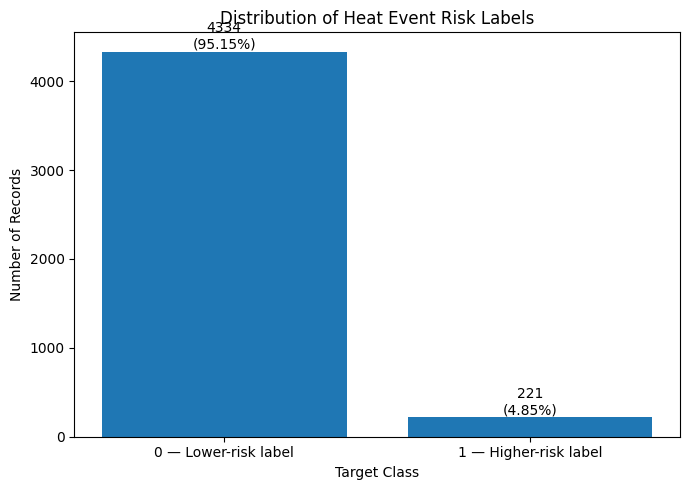

In [65]:
import matplotlib.pyplot as plt

# Visualize the target distribution.
target_counts = (
    df_clean["heat_event_risk"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["0 — Lower-risk label", "1 — Higher-risk label"],
    target_counts.values
)

plt.title("Distribution of Heat Event Risk Labels")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")

for bar, count in zip(bars, target_counts.values):
    percentage = count / len(df_clean) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

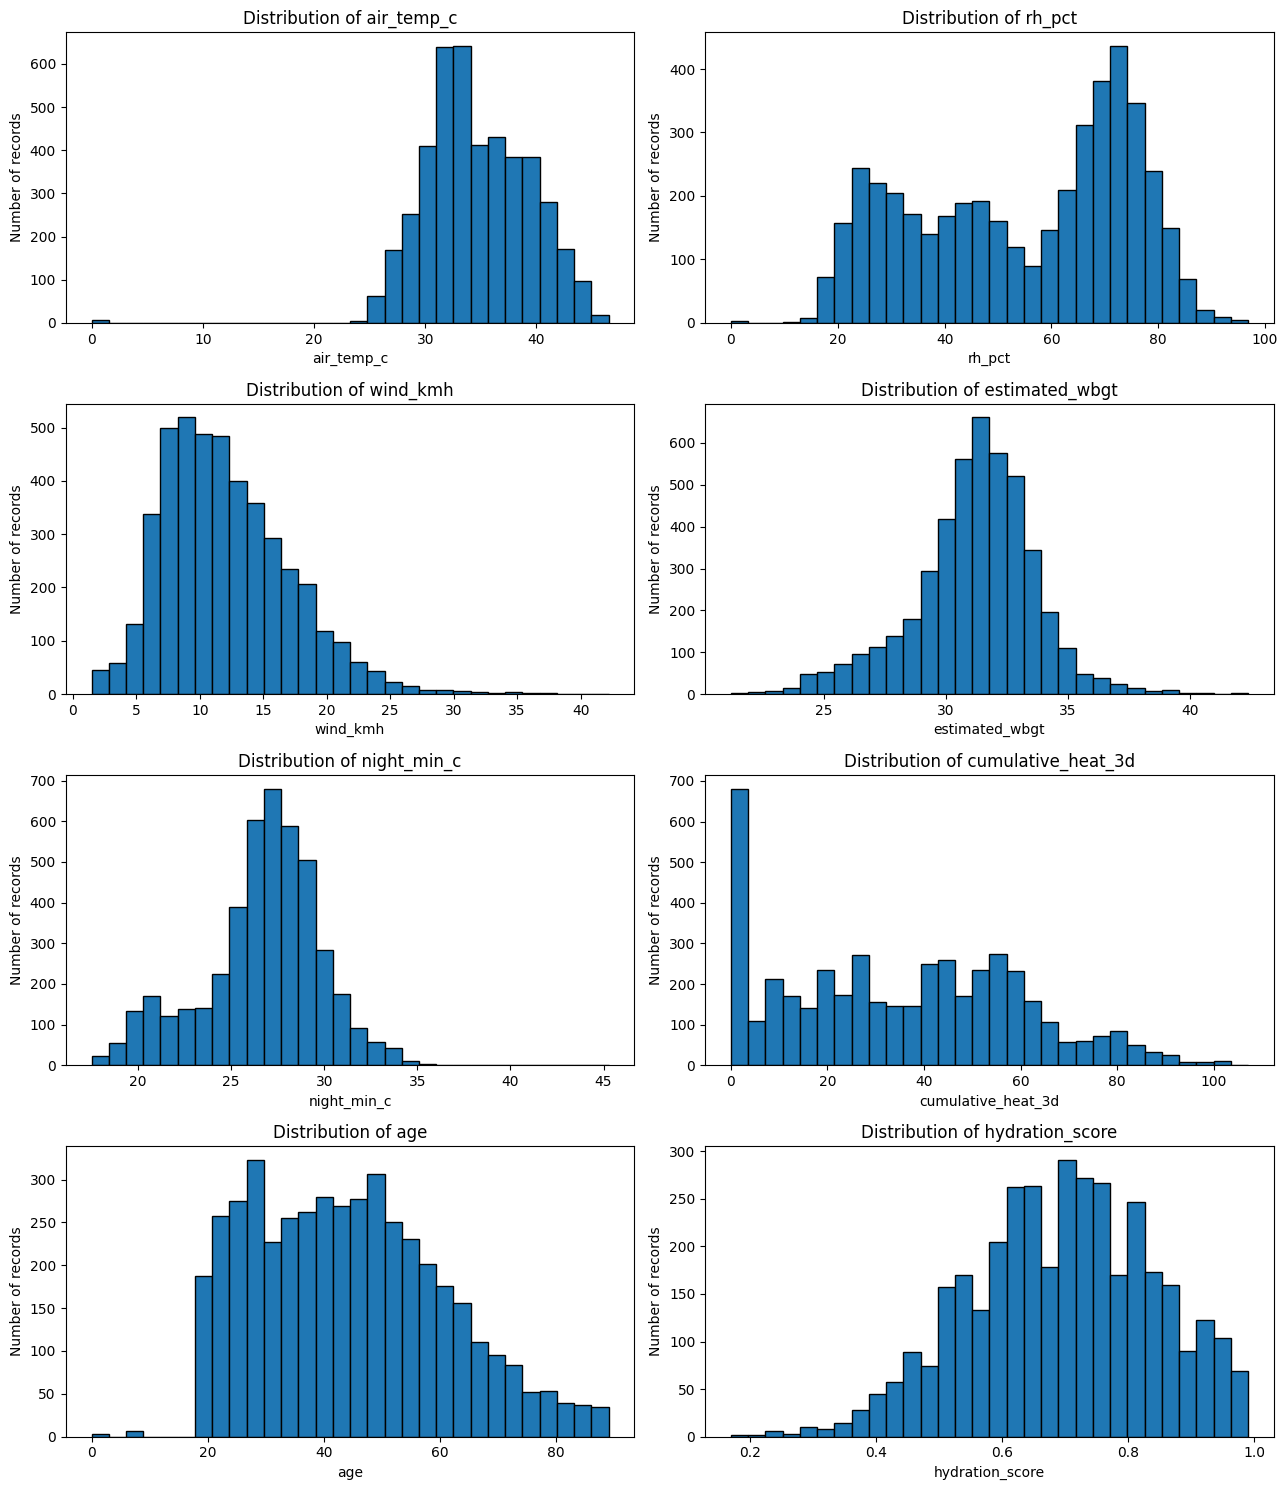

In [66]:
# Plot distributions of key numeric features.
# This is exploratory only; it does not modify df_clean.

numeric_features = [
    "air_temp_c",
    "rh_pct",
    "wind_kmh",
    "estimated_wbgt",
    "night_min_c",
    "cumulative_heat_3d",
    "age",
    "hydration_score"
]

fig, axes = plt.subplots(4, 2, figsize=(13, 15))
axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    values = df_clean[col].dropna()

    ax.hist(values, bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of records")

plt.tight_layout()
plt.show()

In [67]:
# Investigate unusual values identified in the histograms.
# No records or values are modified.

print("1. Unusually low air temperatures (< 10°C)")
display(
    df_clean.loc[
        df_clean["air_temp_c"].notna()
        & (df_clean["air_temp_c"] < 10),
        ["patient_day_id", "city", "date", "air_temp_c",
         "night_min_c", "estimated_wbgt", "heat_event_risk"]
    ].head(15)
)

print("\nCount of air temperatures below 10°C:",
      int((df_clean["air_temp_c"] < 10).sum()))

print("\n2. Ages below 18")
display(
    df_clean.loc[
        df_clean["age"].notna() & (df_clean["age"] < 18),
        ["patient_day_id", "city", "date", "age", "heat_event_risk"]
    ].head(15)
)

print("Count of ages below 18:",
      int((df_clean["age"] < 18).sum()))

print("\n3. Cumulative heat values equal to zero")
display(
    df_clean.loc[
        df_clean["cumulative_heat_3d"].eq(0),
        ["patient_day_id", "city", "date",
         "cumulative_heat_3d", "air_temp_c",
         "estimated_wbgt", "heat_event_risk"]
    ].head(15)
)

print("Count of zero cumulative-heat values:",
      int(df_clean["cumulative_heat_3d"].eq(0).sum()))

1. Unusually low air temperatures (< 10°C)


,patient_day_id,city,date,air_temp_c,night_min_c,estimated_wbgt,heat_event_risk
718,HD100091,Hyderabad,2024-06-08,0.0,23.73,28.64,0
914,HD102964,Jaipur,2024-05-25,0.0,30.87,33.71,0
1359,HD104907,Ahmedabad,2024-06-01,0.0,27.57,32.31,0
1734,HD105373,Lucknow,NaT,0.0,28.34,32.87,0
2147,HD110618,Mumbai,2024-05-18,0.0,26.89,31.84,0
4559,HD101148,Chennai,2024-06-29,0.0,26.86,29.95,0



Count of air temperatures below 10°C: 6

2. Ages below 18


,patient_day_id,city,date,age,heat_event_risk
1210,HD100979,Lucknow,2024-05-08,0,0
1398,HD110329,Hyderabad,2024-06-05,7,0
1750,HD102579,Bengaluru,2024-06-30,0,0
1793,HD108176,Mumbai,2024-11-05,0,0
1874,HD105623,Ahmedabad,2024-05-01,7,0
2220,HD109484,Kolkata,2024-05-24,7,0
2519,HD102643,Mumbai,2024-05-27,7,0
2898,HD110635,Ahmedabad,2024-06-04,7,0
4185,HD104506,Mumbai,2024-05-13,7,0


Count of ages below 18: 9

3. Cumulative heat values equal to zero


,patient_day_id,city,date,cumulative_heat_3d,air_temp_c,estimated_wbgt,heat_event_risk
9,HD107739,Lucknow,2024-05-03,0.0,36.75,26.9,0
12,HD102556,Bengaluru,2024-05-25,0.0,26.86,25.32,0
34,HD101689,Bengaluru,2024-06-09,0.0,27.65,26.04,0
51,HD109847,Hyderabad,2024-06-25,0.0,29.11,28.27,0
60,HD100761,Hyderabad,2024-06-30,0.0,26.61,25.21,0
65,HD106791,Lucknow,2024-05-01,0.0,37.88,27.62,0
71,HD101792,Bengaluru,2024-06-19,0.0,26.39,26.02,0
72,HD100998,Bengaluru,2024-06-14,0.0,27.0,25.63,0
88,HD111376,Bengaluru,2024-05-23,0.0,31.08,29.46,0
90,HD100459,Lucknow,2024-05-04,0.0,34.71,26.14,0


Count of zero cumulative-heat values: 598


In [68]:
# Focused audit of zero values.
# This cell only reports patterns; it does not modify the dataset.

print("1. Records with air_temp_c = 0")
display(
    df_clean.loc[
        df_clean["air_temp_c"].eq(0),
        [
            "patient_day_id", "city", "date", "air_temp_c",
            "rh_pct", "wind_kmh", "night_min_c",
            "estimated_wbgt", "heat_event_risk"
        ]
    ]
)

print("\n2. Records with age = 0")
display(
    df_clean.loc[
        df_clean["age"].eq(0),
        [
            "patient_day_id", "city", "date", "age",
            "pregnant", "chronic_condition", "heat_event_risk"
        ]
    ]
)

print("\n3. Zero cumulative heat by city")
zero_heat = df_clean.loc[df_clean["cumulative_heat_3d"].eq(0)]

display(
    zero_heat.groupby("city").size()
    .sort_values(ascending=False)
    .rename("Zero-value records")
    .to_frame()
)

print("\n4. Target distribution among zero cumulative-heat records")
display(
    zero_heat["heat_event_risk"]
    .value_counts()
    .sort_index()
    .rename("Record count")
    .to_frame()
)

print("\nTotal zero cumulative-heat records:", len(zero_heat))

1. Records with air_temp_c = 0


,patient_day_id,city,date,air_temp_c,rh_pct,wind_kmh,night_min_c,estimated_wbgt,heat_event_risk
718,HD100091,Hyderabad,2024-06-08,0.0,78.5,8.7,23.73,28.64,0
914,HD102964,Jaipur,2024-05-25,0.0,27.3,7.4,30.87,33.71,0
1359,HD104907,Ahmedabad,2024-06-01,0.0,44.4,18.5,27.57,32.31,0
1734,HD105373,Lucknow,NaT,0.0,57.7,9.4,28.34,32.87,0
2147,HD110618,Mumbai,2024-05-18,0.0,78.8,6.5,26.89,31.84,0
4559,HD101148,Chennai,2024-06-29,0.0,72.2,18.8,26.86,29.95,0



2. Records with age = 0


,patient_day_id,city,date,age,pregnant,chronic_condition,heat_event_risk
1210,HD100979,Lucknow,2024-05-08,0,0,0,0
1750,HD102579,Bengaluru,2024-06-30,0,0,1,0
1793,HD108176,Mumbai,2024-11-05,0,0,0,0



3. Zero cumulative heat by city


,Zero-value records
city,
Bengaluru,341
Hyderabad,93
Lucknow,58
Jaipur,48
Delhi,47
Ahmedabad,11



4. Target distribution among zero cumulative-heat records


,Record count
heat_event_risk,
0,585
1,13



Total zero cumulative-heat records: 598


In [69]:
# Compare zero and nonzero cumulative heat by city.
# This is an audit only; no values are modified.

city_heat_audit = (
    df_clean.assign(
        cumulative_heat_is_zero=df_clean["cumulative_heat_3d"].eq(0)
    )
    .groupby("city")
    .agg(
        Total_Records=("cumulative_heat_3d", "size"),
        Zero_Heat_Records=("cumulative_heat_is_zero", "sum")
    )
)

city_heat_audit["Zero_Heat_Percentage"] = (
    city_heat_audit["Zero_Heat_Records"]
    / city_heat_audit["Total_Records"]
    * 100
).round(2)

city_heat_audit = city_heat_audit.sort_values(
    "Zero_Heat_Percentage",
    ascending=False
)

display(city_heat_audit)

print(
    "\nOverall zero cumulative-heat percentage:",
    round(df_clean["cumulative_heat_3d"].eq(0).mean() * 100, 2),
    "%"
)

,Total_Records,Zero_Heat_Records,Zero_Heat_Percentage
city,,,
Bengaluru,491,341,69.45
Hyderabad,488,93,19.06
Lucknow,483,58,12.01
Jaipur,487,48,9.86
Delhi,534,47,8.80
Ahmedabad,557,11,1.97
Chennai,525,0,0.00
Kolkata,452,0,0.00
Mumbai,538,0,0.00



Overall zero cumulative-heat percentage: 13.13 %


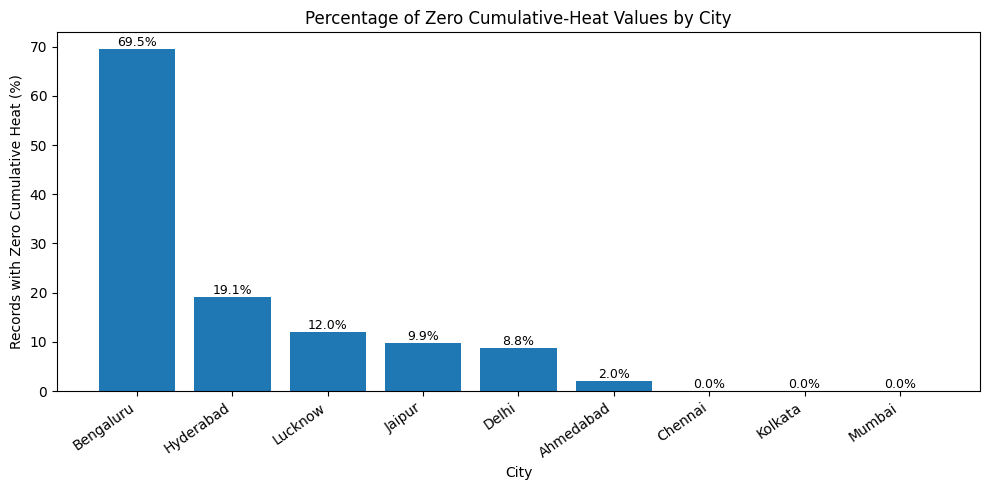

In [70]:
# Visualize the percentage of records with zero cumulative heat by city.
# Uses the city_heat_audit table created in Cell 56.

plt.figure(figsize=(10, 5))

bars = plt.bar(
    city_heat_audit.index,
    city_heat_audit["Zero_Heat_Percentage"]
)

plt.title("Percentage of Zero Cumulative-Heat Values by City")
plt.xlabel("City")
plt.ylabel("Records with Zero Cumulative Heat (%)")
plt.xticks(rotation=35, ha="right")

for bar, percentage in zip(
    bars,
    city_heat_audit["Zero_Heat_Percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [71]:
# Inspect columns before ML training.
# This is an audit only; it does not change the dataset.

print("Dataset shape:", df_clean.shape)

print("\nAll columns:")
for col in df_clean.columns:
    print(f"- {col}")

print("\nTarget column:")
print("heat_event_risk")

print("\nIdentifier columns:")
display(
    df_clean[
        ["patient_day_id", "patient_day_id_original"]
    ].head(10)
)

print("\nColumns with 'risk', 'label', 'event', or 'target' in the name:")
display([
    col for col in df_clean.columns
    if any(term in col.lower()
           for term in ["risk", "label", "event", "target"])
])

Dataset shape: (4555, 39)

All columns:
- patient_day_id
- city
- date
- air_temp_c
- rh_pct
- wind_kmh
- solar_wm2
- rain_last_24h_mm
- pm25_ugm3
- ozone_ppb
- no2_ppb
- night_min_c
- estimated_wbgt
- cumulative_heat_3d
- age
- gender
- pregnant
- chronic_condition
- heart_disease
- diabetes
- ckd
- diuretic
- beta_blocker
- outdoor_work
- exertion_level
- hydration_score
- acclimatized
- headache
- dizziness
- nausea
- wbgt_mean_v2_c
- wbgt_max_v2_c
- wbgt_min_v2_c
- temperature_max_v2_c
- shortwave_mean_v2_wm2
- shortwave_max_v2_wm2
- elevation_v2_m
- heat_event_risk
- patient_day_id_original

Target column:
heat_event_risk

Identifier columns:


,patient_day_id,patient_day_id_original
0,HD100976,HD100976
1,HD107746,HD107746
2,HD100257,HD100257
3,HD107922,HD107922
4,HD110666,HD110666
5,hd101895,hd101895
6,HD107835,HD107835
7,HD105563,HD105563
8,HD102289,HD102289
9,HD107739,HD107739



Columns with 'risk', 'label', 'event', or 'target' in the name:


['heat_event_risk']

In [72]:
# Standardize identifier capitalization and audit repeated IDs.
# No records are removed in this cell.

df_clean["patient_day_id"] = (
    df_clean["patient_day_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Unique patient-day IDs:", df_clean["patient_day_id"].nunique())
print("Total rows:", len(df_clean))

repeated_id_mask = df_clean["patient_day_id"].duplicated(keep=False)
repeated_id_records = df_clean.loc[
    repeated_id_mask,
    [
        "patient_day_id",
        "city",
        "date",
        "age",
        "rh_pct",
        "heat_event_risk"
    ]
].sort_values("patient_day_id")

print("Rows with a repeated patient-day ID:", len(repeated_id_records))
display(repeated_id_records.head(20))

Unique patient-day IDs: 4528
Total rows: 4555
Rows with a repeated patient-day ID: 54


,patient_day_id,city,date,age,rh_pct,heat_event_risk
1110,HD100052,Delhi,2024-05-22,40,36.8,0
2859,HD100052,Delhi,2024-05-22,39,34.5,0
1743,HD100229,Bengaluru,2024-05-11,34,72.3,0
2721,HD100229,Bengaluru,2024-05-11,35,74.3,0
2624,HD100885,Bengaluru,2024-06-03,<NA>,72.4,0
3434,HD100885,Bengaluru,2024-06-03,<NA>,74.8,0
3010,HD101575,Delhi,2024-05-13,86,42.7,0
3899,HD101575,Delhi,2024-05-13,85,40.0,0
1222,HD101683,Bengaluru,2024-06-11,58,73.8,0
3196,HD101683,Bengaluru,2024-06-11,57,74.1,0


In [73]:
# Prepare a feature inventory for the Member 2 handoff.
# This does not modify df_clean or train a model.

target_column = "heat_event_risk"

excluded_columns = [
    "patient_day_id",
    "patient_day_id_original",
    "date",
    target_column
]

X = df_clean.drop(columns=excluded_columns).copy()
y = df_clean[target_column].copy()

print("Cleaned dataset shape:", df_clean.shape)
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeature columns:")
for col in X.columns:
    print("-", col)

print("\nMissing values in features:", int(X.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))

print("\nFeature data types:")
display(X.dtypes.astype(str).rename("Data Type").to_frame())

Cleaned dataset shape: (4555, 39)
Feature matrix shape: (4555, 35)
Target vector shape: (4555,)

Feature columns:
- city
- air_temp_c
- rh_pct
- wind_kmh
- solar_wm2
- rain_last_24h_mm
- pm25_ugm3
- ozone_ppb
- no2_ppb
- night_min_c
- estimated_wbgt
- cumulative_heat_3d
- age
- gender
- pregnant
- chronic_condition
- heart_disease
- diabetes
- ckd
- diuretic
- beta_blocker
- outdoor_work
- exertion_level
- hydration_score
- acclimatized
- headache
- dizziness
- nausea
- wbgt_mean_v2_c
- wbgt_max_v2_c
- wbgt_min_v2_c
- temperature_max_v2_c
- shortwave_mean_v2_wm2
- shortwave_max_v2_wm2
- elevation_v2_m

Missing values in features: 4832
Missing target values: 0

Feature data types:


,Data Type
city,str
air_temp_c,Float64
rh_pct,Float64
wind_kmh,Float64
solar_wm2,float64
rain_last_24h_mm,Float64
pm25_ugm3,Float64
ozone_ppb,Float64
no2_ppb,Float64
night_min_c,Float64


In [74]:
# Export the cleaned dataset for Member 2.
# Keep the original raw df unchanged.

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLEANED_DATA_PATH = OUTPUT_DIR / "heatguard_cleaned.csv"

df_export = df_clean.drop(
    columns=["patient_day_id_original"]
).copy()

df_export.to_csv(CLEANED_DATA_PATH, index=False)

print("Cleaned dataset exported successfully.")
print("File:", CLEANED_DATA_PATH)
print("Exported shape:", df_export.shape)
print("Target column included:", "heat_event_risk" in df_export.columns)
print("Audit-only original ID excluded:", "patient_day_id_original" not in df_export.columns)
print("Missing target values:", int(df_export["heat_event_risk"].isna().sum()))

Cleaned dataset exported successfully.
File: c:\HeatGuard\outputs\heatguard_cleaned.csv
Exported shape: (4555, 38)
Target column included: True
Audit-only original ID excluded: True
Missing target values: 0


In [75]:
# Save a data-quality summary for the Member 2 handoff.

MISSING_REPORT_PATH = OUTPUT_DIR / "missing_values_report.csv"

missing_summary.to_csv(MISSING_REPORT_PATH, index=True)

print("Missing-value report exported.")
print("File:", MISSING_REPORT_PATH)
print("Columns in report:", missing_summary.shape[0])
print("\nColumns with the most missing values:")
display(missing_summary.head(10))

Missing-value report exported.
File: c:\HeatGuard\outputs\missing_values_report.csv
Columns in report: 39

Columns with the most missing values:


,Missing Count,Missing Percentage,Data Type
hydration_score,882,19.36,Float64
pm25_ugm3,306,6.72,Float64
ozone_ppb,301,6.61,Float64
no2_ppb,299,6.56,Float64
solar_wm2,265,5.82,float64
acclimatized,228,5.01,Int64
air_temp_c,194,4.26,Float64
rain_last_24h_mm,138,3.03,Float64
outdoor_work,138,3.03,Int64
exertion_level,136,2.99,str
